# ShelfIt — Data Preparation & Exploratory Data Analysis
**Data Analytics (MGB) · Individual Submission · Syamantak Dey**

*ShelfIt: fulfilment-as-a-service for UAE social-commerce sellers — "You sell. We shelf it."*

| Section | Rubric item |
|---|---|
| 1. Business context & data generation | Synthetic data to validate the idea (10) |
| 2–4. Data audit, cleaning, transformation | Data cleaning & transformation (10) |
| 5–8. Descriptive & diagnostic analytics, correlation | EDA with explained graphs (30) |
| 9. Summary of insights | Business strategy diagnosis |

**Business questions this EDA answers**
1. Does the simulated business behave like the business plan (≈ AED 3,200 revenue/seller, ≈ AED 10/order)?
2. Who are ShelfIt's sellers and where does revenue come from?
3. **Why do sellers churn?** (diagnostic)
4. What drives revenue per seller? (diagnostic)
5. Which services are used together, and by whom?

---
## 0. Setup

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import warnings; warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50); pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid', font_scale=0.95)
PAL = ['#2E5AAC', '#E07A3F', '#3FA27A', '#C4455A', '#7E5BB5', '#8C8C8C']
sns.set_palette(PAL)
FIG = 'figures/'
def save(name): plt.tight_layout(); plt.savefig(FIG + name, dpi=150, bbox_inches='tight'); plt.show()

---
## 1. Business context & the synthetic data

ShelfIt stores stock, picks/packs orders in the seller's branding, and ships same/next-day across the UAE with cash-on-delivery (COD) collection. Revenue = storage (AED 150–300/shelf) + pick & pack (AED 5–8/order) + delivery margin (AED 3–5/order) + value-added services.

**Why synthetic data?** ShelfIt is pre-launch, so no real data exists. The data was generated in Python (`generate_data.py`) with every rule taken from the business plan, so the analysis *validates the plan's own assumptions*:

| Rule in generator | Source in business plan |
|---|---|
| 5 segments: Beauty 28%, Fashion 24%, Gadgets 20%, Gifting 16%, Food 12% | Target customer segments |
| Orders/month lognormal, 5–1,200 | ICP: 5–1,000 orders/month |
| Plan by volume: Starter <150, Growth 150–600, Pro 600+ | Pricing plans |
| Revenue = shelves × fee + orders × (AED 5–8 + AED 3–5) + VAS jobs + noise | Revenue model & unit economics |
| Churn = logistic f(CSAT, dispatch, COD payout delay, tenure, volume, plan) | Problem statement (courier chaos, slow COD) |
| Service baskets follow segment needs (gifting → fragile/gift wrap; beauty/food → temp control) | Segment "key needs" table |

Then `make_raw.py` injected **realistic data-quality problems** (the kind you get from a WhatsApp bot + manual Google-Sheet export) so that cleaning is a genuine step.

Two tables: **Sellers** (one row per seller) and **Orders** (one row per order, 0/1 flag per service).

In [2]:
raw = pd.read_csv('data/shelfit_sellers_raw.csv')
orders_raw = pd.read_csv('data/shelfit_orders_raw.csv')
print('Sellers raw:', raw.shape, '| Orders raw:', orders_raw.shape)
raw.head()

Sellers raw: (412, 19) | Orders raw: (5785, 15)


,seller_id,signup_date,segment,sales_platform,emirate,plan,shelves_rented,monthly_orders,avg_order_value_aed,cod_share,return_rate,on_time_dispatch_rate,support_tickets_month,value_added_jobs_month,dashboard_logins_month,cod_remittance_days,satisfaction_score,monthly_revenue_aed,churned
0,S0279,30/08/2025,Home & Gifting,Instagram,Abu dhabi,Growth,2,258,153.0,0.45,0.067,0.925,2,2,12,2.6,4.2,"AED 3,123",N
1,S0383,22/03/2025,Home & Gifting,TikTok,Dubai,Growth,3,415,101.0,0.81,0.060,0.992,6,4,3,1.9,7.0,"AED 5,707",0
2,S0369,26/10/2025,Modest Fashion,Instagram,Ajman,Growth,2,263,166.0,0.50,0.136,0.966,3,3,12,NaN,6.9,2885.0,No
3,S0263,2026-06-05,Modest Fashion,Instagram,Dubai,Growth,2,398,NaN,0.72,0.144,0.902,6,0,18,3.7,2.3,"AED 4,660",Yes
4,S0298,08/11/2025,Home & Gifting,TikTok,Ajman,Starter,1,60,166.0,0.81,0.022,0.964,1,3,14,4.7,7.4,1021.0,0


---
## 2. Data quality audit
Before changing anything, profile every column: type, missing values, cardinality and duplicates.

In [3]:
audit = pd.DataFrame({
    'dtype': raw.dtypes.astype(str),
    'missing': raw.isna().sum(),
    'missing_%': (raw.isna().mean()*100).round(1),
    'unique': raw.nunique()})
print('Duplicate seller rows:', raw.duplicated().sum(), '| Duplicate order rows:', orders_raw.duplicated().sum())
audit

Duplicate seller rows: 12 | Duplicate order rows: 40


,dtype,missing,missing_%,unique
seller_id,str,0,0.0,400
signup_date,str,0,0.0,347
segment,str,0,0.0,10
sales_platform,str,0,0.0,5
emirate,str,8,1.9,11
plan,str,0,0.0,6
shelves_rented,int64,0,0.0,10
monthly_orders,int64,0,0.0,286
avg_order_value_aed,float64,13,3.2,197
cod_share,float64,0,0.0,68


**Findings from the audit**
- **12 duplicate seller rows** and **40 duplicate orders** (double export).
- **Missing values:** satisfaction 5.1%, COD remittance days 4.4%, order value 3.2%, emirate 1.9%.
- **Wrong types:** `monthly_revenue_aed` and `churned` are text; `signup_date` is text.
- **Cardinality too high:** `emirate` has 11 unique values for 4 emirates, `segment` 10 for 5, `plan` 6 for 3 → inconsistent labels (checked below).

In [4]:
for c in ['emirate', 'segment', 'plan', 'sales_platform', 'churned']:
    print(c, '->', sorted(raw[c].dropna().astype(str).unique()), '\n')

emirate -> [' Dubai', 'AUH', 'Abu Dhabi', 'Abu dhabi', 'Ajman', 'DXB', 'Dubai', 'SHJ', 'Sharjah', 'dubai', 'sharjah'] 

segment -> ['Accessories & Gadgets', 'Beauty & Fragrance', 'Home & Gifting', 'Modest Fashion', 'Packaged Food', 'accessories and gadgets', 'beauty and fragrance', 'home and gifting', 'modest fashion', 'packaged food'] 

plan -> ['GROWTH ', 'Growth', 'PRO ', 'Pro', 'STARTER ', 'Starter'] 

sales_platform -> ['Instagram', 'Instagram + TikTok', 'Instagram+TikTok', 'TikTok', 'WhatsApp'] 

churned -> ['0', '1', 'N', 'No', 'Y', 'Yes', 'yes'] 



Confirmed: the same category is spelled several ways (`DXB` / `dubai` / ` Dubai`, `PRO ` with a trailing space, `Yes`/`Y`/`1` for churn). Grouping on these would split one group into many.

In [5]:
raw[['monthly_orders', 'return_rate', 'satisfaction_score']].describe().T

,count,mean,std,min,25%,50%,75%,max
monthly_orders,412.0,1042.174757,8489.872458,-534.0,137.250,246.000,419.000,99999.0
return_rate,412.0,0.180046,0.971318,0.0,0.039,0.057,0.098,14.1
satisfaction_score,391.0,5.182097,4.996757,-1.0,4.000,5.000,6.000,99.0


**Impossible values:** negative orders (min −534), orders = 99,999 (a placeholder), return rate up to 14.1 (a % typed instead of a fraction), satisfaction of −1, 0 and 99 on a 1–10 scale. These would distort every mean and correlation, so they must be fixed before EDA.

---
## 3. Data cleaning
Each step is logged. Every choice is a **business rule**, not an arbitrary default:

| Problem | Treatment | Why |
|---|---|---|
| Duplicates | Drop exact duplicates; assert `seller_id` unique | Double counting inflates revenue |
| Inconsistent labels | Strip, title-case, map codes (DXB→Dubai) | One category = one label |
| Text numbers / mixed churn codes / 2 date formats | Parse to float, 0/1, datetime | Needed for maths |
| Negative orders | Absolute value | Sign-entry error; magnitude is plausible |
| Orders = 99,999 | Set missing, then **re-estimate from revenue** ÷ AED 10.5/order | Revenue is fee-driven, so this is more accurate than a median |
| Return rate > 0.4 | ÷ 100 | Was typed as a %; no seller returns >40% |
| CSAT outside 1–10 | Set missing | Outside the scale |
| Missing CSAT / order value / COD days | **Median within segment** | Distributions are skewed and differ by segment |
| Missing emirate | Mode (Dubai) | Only 8 rows; Dubai is the majority |

In [6]:
df = raw.copy(); log = []
def step(msg, before): log.append({'step': msg, 'rows_before': before, 'rows_after': len(df)})

# 1. Duplicates
b = len(df); df = df.drop_duplicates(); step('Removed exact duplicate rows', b)
assert df.seller_id.is_unique

# 2. Standardise text categories
df['emirate'] = (df.emirate.str.strip().str.title()
                 .replace({'Dxb': 'Dubai', 'Shj': 'Sharjah', 'Auh': 'Abu Dhabi'}))
seg_map = {s.lower().replace('&', 'and'): s for s in ['Beauty & Fragrance', 'Modest Fashion',
           'Accessories & Gadgets', 'Home & Gifting', 'Packaged Food']}
df['segment'] = df.segment.apply(lambda s: seg_map.get(s.lower().replace('&', 'and'), s))
df['plan'] = df.plan.str.strip().str.title()
df['sales_platform'] = df.sales_platform.replace({'Instagram+TikTok': 'Instagram + TikTok'})
step('Standardised emirate / segment / plan / platform labels', len(df))

# 3. Fix data types
df['monthly_revenue_aed'] = df.monthly_revenue_aed.astype(str).str.replace('AED', '').str.replace(',', '').str.strip().astype(float)
df['churned'] = df.churned.astype(str).str.strip().str.lower().map({'1': 1, 'yes': 1, 'y': 1, '0': 0, 'no': 0, 'n': 0}).astype(int)
df['signup_date'] = pd.to_datetime(df.signup_date, format='%Y-%m-%d', errors='coerce').fillna(
                    pd.to_datetime(df.signup_date, format='%d/%m/%Y', errors='coerce'))   # two date formats in export
step('Converted revenue to numeric, churn to 0/1, signup_date to datetime', len(df))

# 4. Invalid values -> NaN, then fix
df.loc[df.monthly_orders < 0, 'monthly_orders'] = df.monthly_orders.abs()   # sign-entry error
df.loc[df.monthly_orders > 5000, 'monthly_orders'] = np.nan                  # impossible for a small seller
df.loc[df.return_rate > 0.4, 'return_rate'] = df.return_rate / 100             # entered as % (no seller returns >40%)
df.loc[~df.satisfaction_score.between(1, 10), 'satisfaction_score'] = np.nan # outside 1-10 scale
step('Fixed negative/impossible orders, % return rates, out-of-scale CSAT', len(df))

# 5. Impute missing values
print('Missing before imputation:\n', df.isna().sum()[lambda x: x > 0])
# orders: back-solve from revenue using the plan's fee structure (≈ AED 10/order) – better than a median
est = ((df.monthly_revenue_aed - df.shelves_rented*180) / 10.5).round()
df['monthly_orders'] = df.monthly_orders.fillna(est)
for c in ['satisfaction_score', 'avg_order_value_aed', 'cod_remittance_days']:
    df[c] = df[c].fillna(df.groupby('segment')[c].transform('median'))   # segment-wise median (skew-robust)
df['emirate'] = df.emirate.fillna(df.emirate.mode()[0])
step('Imputed missing values (segment medians / mode / fee-based estimate)', len(df))
print('Missing after:', df.isna().sum().sum())
pd.DataFrame(log)

Missing before imputation:
 emirate                 8
monthly_orders          3
avg_order_value_aed    12
cod_remittance_days    16
satisfaction_score     23
dtype: int64
Missing after: 0


,step,rows_before,rows_after
0,Removed exact duplicate rows,412,400
1,Standardised emirate / segment / plan / platfo...,400,400
2,"Converted revenue to numeric, churn to 0/1, si...",400,400
3,"Fixed negative/impossible orders, % return rat...",400,400
4,Imputed missing values (segment medians / mode...,400,400


Result: **400 unique sellers, 0 missing values**, all fields in valid ranges and correct types.

Orders table: remove the 40 duplicate orders and check referential integrity (every order belongs to a known seller).

In [7]:
orders = orders_raw.drop_duplicates().reset_index(drop=True)
SERVICES = [c for c in orders.columns if c not in ['order_id', 'seller_id', 'segment', 'services_list']]
assert orders.order_id.is_unique and orders.seller_id.isin(df.seller_id).all()
print('Orders after de-dup:', orders.shape, '| services:', len(SERVICES))

Orders after de-dup: (5745, 15) | services: 11


---
## 4. Data transformation & feature engineering

| New feature | Formula | Business meaning |
|---|---|---|
| `tenure_months` | months from signup to 31-Oct-2026 | Loyalty / lifecycle stage |
| `revenue_per_order` | revenue ÷ orders | ShelfIt's unit economics |
| `orders_per_shelf` | orders ÷ shelves | Space efficiency (upsell signal) |
| `est_gmv_aed` | orders × order value | Size of the seller's own business |
| `tickets_per_100_orders` | tickets ÷ orders × 100 | Service problems *adjusted for size* |
| `plan_level` | Starter=1, Growth=2, Pro=3 | Ordinal encoding |
| `tenure_band`, `csat_band` | binning | Readable segments for charts |
| `log_orders` | log(1 + orders) | Reduces right skew for later models |

A **model-ready** copy is also saved with one-hot encoded categories and z-score scaled numerics, ready for classification/clustering in the group phase.

In [8]:
# Feature engineering
ref = pd.Timestamp('2026-10-31')
df['tenure_months'] = np.ceil((ref - df.signup_date).dt.days / 30.44).astype(int)
df['revenue_per_order'] = (df.monthly_revenue_aed / df.monthly_orders).round(2)
df['orders_per_shelf'] = (df.monthly_orders / df.shelves_rented).round(1)
df['est_gmv_aed'] = (df.monthly_orders * df.avg_order_value_aed).round(0)       # seller's own sales
df['tickets_per_100_orders'] = (df.support_tickets_month / df.monthly_orders * 100).round(2)
df['plan_level'] = df.plan.map({'Starter': 1, 'Growth': 2, 'Pro': 3})           # ordinal encoding
df['tenure_band'] = pd.cut(df.tenure_months, [0, 6, 12, 24, 99], labels=['0-6m', '7-12m', '13-24m', '25m+'])
df['csat_band'] = pd.cut(df.satisfaction_score, [0, 4, 6, 10], labels=['Low (≤4)', 'Mid (4-6)', 'High (>6)'])
df['log_orders'] = np.log1p(df.monthly_orders)                                  # tame right skew

# Model-ready copy: one-hot encoding + z-score scaling
from sklearn.preprocessing import StandardScaler
num_cols = ['monthly_orders', 'avg_order_value_aed', 'cod_share', 'return_rate', 'on_time_dispatch_rate',
            'support_tickets_month', 'value_added_jobs_month', 'dashboard_logins_month',
            'cod_remittance_days', 'satisfaction_score', 'tenure_months', 'shelves_rented']
model_df = pd.get_dummies(df.drop(columns=['signup_date', 'tenure_band', 'csat_band']),
                          columns=['segment', 'sales_platform', 'emirate', 'plan'], drop_first=True)
model_df[num_cols] = StandardScaler().fit_transform(model_df[num_cols])
df.to_csv('data/shelfit_sellers_clean.csv', index=False)
model_df.to_csv('data/shelfit_sellers_model_ready.csv', index=False)
orders.to_csv('data/shelfit_orders_clean.csv', index=False)
print('Clean:', df.shape, '| Model-ready:', model_df.shape)
df[['tenure_months', 'revenue_per_order', 'orders_per_shelf', 'est_gmv_aed', 'tickets_per_100_orders']].describe().round(2).T

Clean: (400, 28) | Model-ready: (400, 33)


,count,mean,std,min,25%,50%,75%,max
tenure_months,400.0,13.44,7.09,2.00,7.00,13.00,20.00,25.00
revenue_per_order,400.0,13.34,2.98,3.16,11.80,12.90,14.40,48.56
orders_per_shelf,400.0,108.67,54.98,21.00,70.95,97.60,134.12,534.00
est_gmv_aed,400.0,52834.65,53653.42,1407.00,19153.50,34046.00,67866.75,373200.00
tickets_per_100_orders,400.0,1.80,1.82,0.00,0.76,1.25,2.16,17.65


Revenue per order has a median of **AED 12.90** — in line with the plan's AED 10 pick/pack + delivery margin plus storage and VAS income spread across orders. A typical shelf handles ~98 orders/month.

---
## 5. Descriptive analytics
### 5.1 Business KPI snapshot

In [9]:
kpi = {'Active sellers': len(df), 'Total monthly orders': int(df.monthly_orders.sum()),
       'Monthly revenue (AED)': int(df.monthly_revenue_aed.sum()),
       'Avg revenue / seller (AED)': round(df.monthly_revenue_aed.mean()),
       'Avg revenue / order (AED)': round(df.monthly_revenue_aed.sum()/df.monthly_orders.sum(), 2),
       'Churn rate': f"{df.churned.mean():.1%}", 'Avg CSAT': round(df.satisfaction_score.mean(), 2),
       'On-time dispatch': f"{df.on_time_dispatch_rate.mean():.1%}"}
pd.Series(kpi, name='value').to_frame()

,value
Active sellers,400
Total monthly orders,127340
Monthly revenue (AED),1587743
Avg revenue / seller (AED),3969
Avg revenue / order (AED),12.47
Churn rate,18.8%
Avg CSAT,4.99
On-time dispatch,93.0%


**Plan validation:** average revenue per seller is **AED 3,969** vs. the plan's AED 3,200 assumption, and 400 sellers would generate ~AED 1.59 M/month. The one warning sign is an **18.8% churn rate** and a mediocre average satisfaction of **5.0/10** — retention is the main risk, which the diagnostic section investigates.

### 5.2 Summary statistics

In [10]:
desc = df[num_cols + ['monthly_revenue_aed']].describe().T
desc['skew'] = df[num_cols + ['monthly_revenue_aed']].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
monthly_orders,400.0,318.35,264.31,21.00,140.00,245.50,406.25,1200.00,1.68
avg_order_value_aed,400.0,165.36,72.91,35.00,101.00,159.50,216.00,394.00,0.43
cod_share,400.0,0.60,0.15,0.17,0.50,0.60,0.72,0.95,-0.08
return_rate,400.0,0.06,0.04,0.00,0.04,0.06,0.09,0.18,0.55
on_time_dispatch_rate,400.0,0.93,0.04,0.82,0.90,0.93,0.96,1.00,-0.14
support_tickets_month,400.0,3.72,2.37,0.00,2.00,3.00,5.00,17.00,1.29
value_added_jobs_month,400.0,1.78,1.45,0.00,1.00,1.00,3.00,7.00,0.73
dashboard_logins_month,400.0,11.10,5.98,0.00,7.00,11.00,15.00,27.00,0.28
cod_remittance_days,400.0,3.09,0.94,1.00,2.50,3.00,3.70,6.30,0.21
satisfaction_score,400.0,4.99,1.43,1.00,4.00,5.00,5.93,8.60,-0.21


- **Orders and revenue are right-skewed** (skew ≈ 1.7): mean (318 orders) > median (246). A few large sellers pull the average up, so medians are better for "typical seller" statements.
- Return rate, COD share, dispatch and CSAT are roughly symmetric.
- Average COD share is **60%** — most end customers pay cash, so fast COD remittance matters to sellers' cash flow.

### 5.3 Distribution of orders and revenue

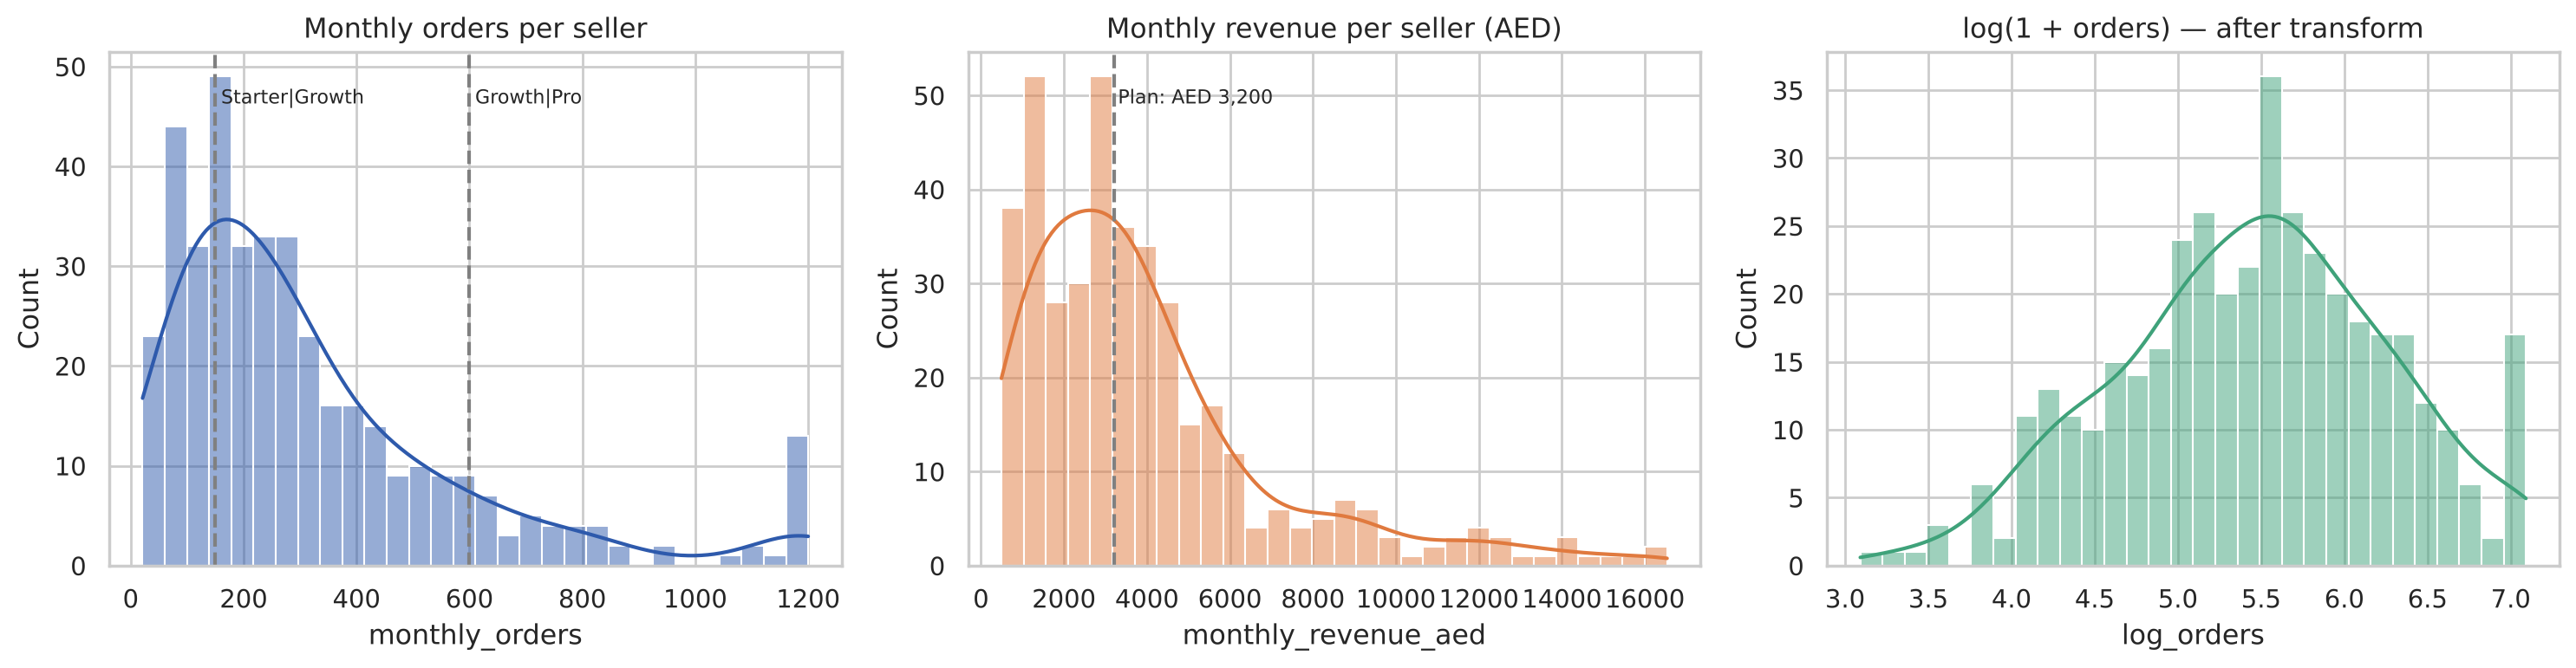

Skew orders: 1.68 | skew log_orders: -0.14
Median orders: 245.5 | Median revenue: 3167.0


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df.monthly_orders, bins=30, kde=True, ax=ax[0], color=PAL[0]); ax[0].set_title('Monthly orders per seller')
for x, l in [(150, 'Starter|Growth'), (600, 'Growth|Pro')]: ax[0].axvline(x, ls='--', c='grey'); ax[0].text(x+10, ax[0].get_ylim()[1]*.9, l, fontsize=8)
sns.histplot(df.monthly_revenue_aed, bins=30, kde=True, ax=ax[1], color=PAL[1]); ax[1].set_title('Monthly revenue per seller (AED)')
ax[1].axvline(3200, ls='--', c='grey'); ax[1].text(3300, ax[1].get_ylim()[1]*.9, 'Plan: AED 3,200', fontsize=8)
sns.histplot(df.log_orders, bins=30, kde=True, ax=ax[2], color=PAL[2]); ax[2].set_title('log(1 + orders) — after transform')
save('01_distributions.png')
print('Skew orders:', round(df.monthly_orders.skew(), 2), '| skew log_orders:', round(df.log_orders.skew(), 2))
print('Median orders:', df.monthly_orders.median(), '| Median revenue:', df.monthly_revenue_aed.median())

**Interpretation**
- **Left/middle:** a long right tail — most sellers do 100–400 orders/month, very few exceed 600 (Pro territory). Revenue mirrors orders almost exactly because ShelfIt charges per order.
- The median seller (AED 3,167/month) sits right on the plan's AED 3,200 assumption (dashed line), supporting the unit economics.
- **Right:** after a log transform the skew drops from 1.68 to −0.14 (near normal). This justifies using `log_orders` in regression/clustering later.

### 5.4 Seller mix

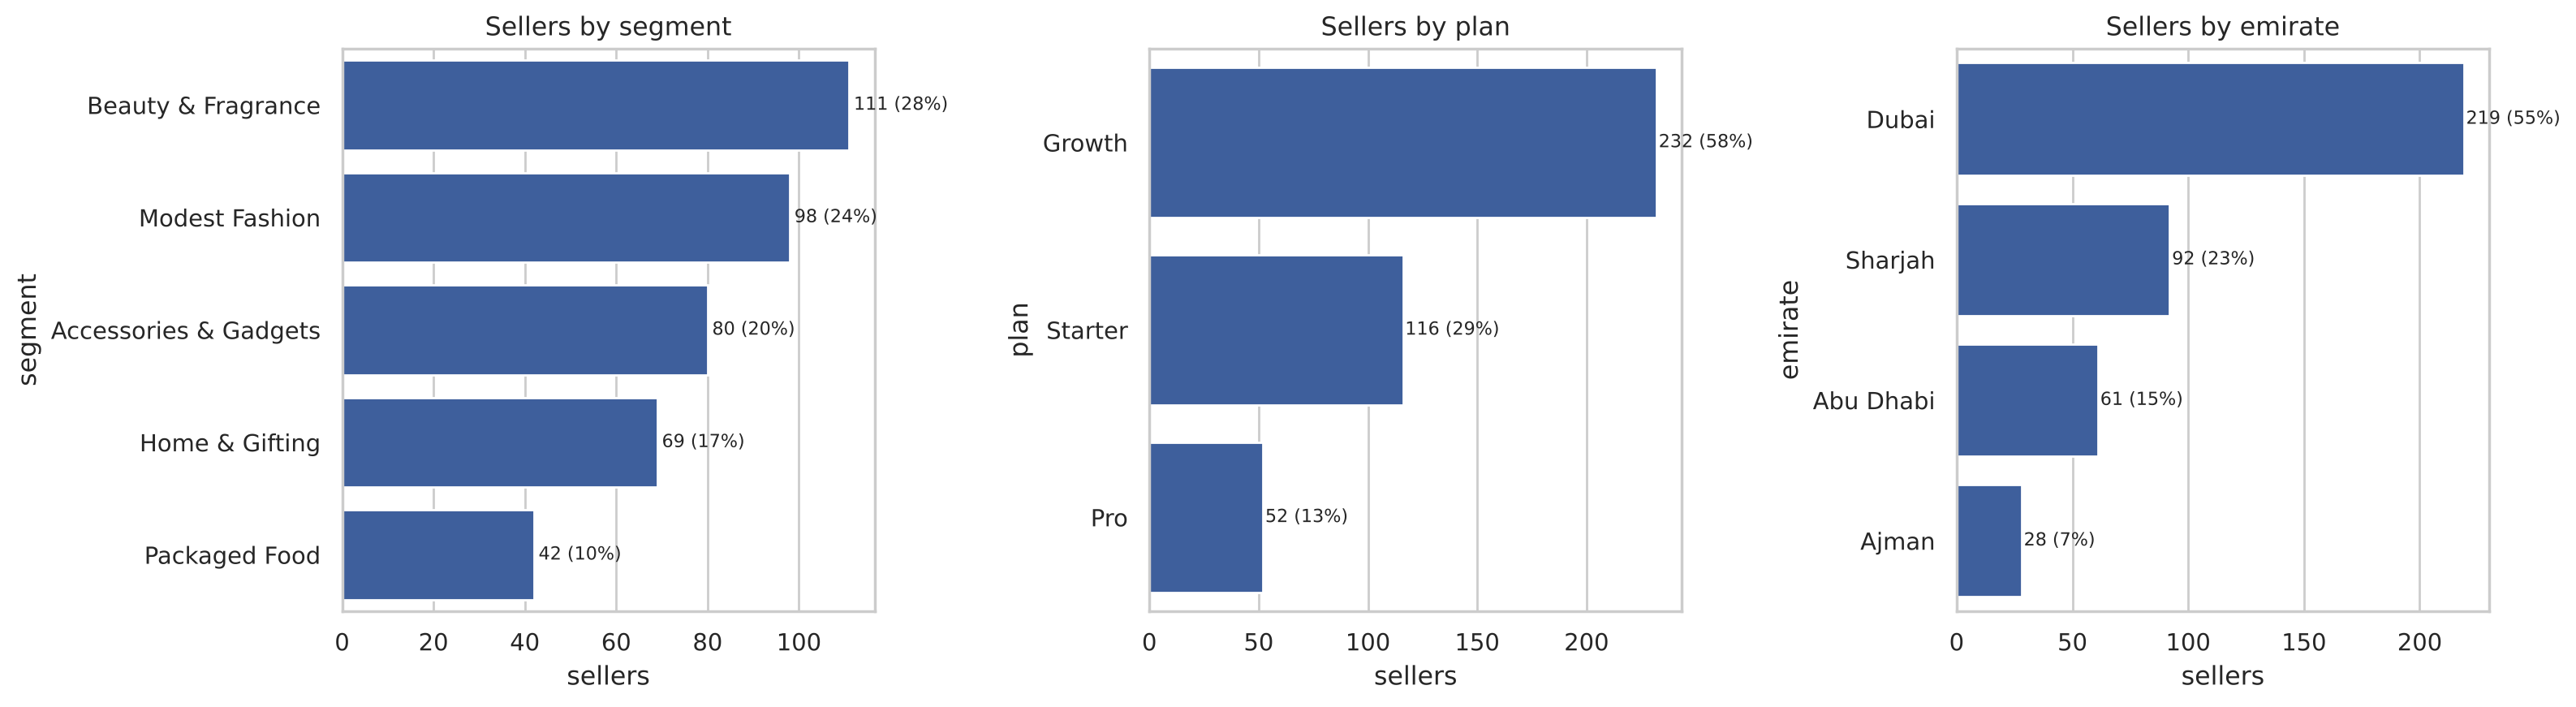

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, c in zip(ax, ['segment', 'plan', 'emirate']):
    vc = df[c].value_counts(); sns.barplot(x=vc.values, y=vc.index, ax=a, color=PAL[0])
    for i, v in enumerate(vc.values): a.text(v+1, i, f'{v} ({v/len(df):.0%})', va='center', fontsize=8)
    a.set_title(f'Sellers by {c}'); a.set_xlabel('sellers')
save('02_seller_mix.png')

**Interpretation**
- Beauty & Fragrance (28%) and Modest Fashion (25%) are the core customer base — consistent with the plan's target segments.
- **58% of sellers are on Growth**, 29% Starter, only 13% Pro.
- **Dubai = 55%** of sellers; Sharjah is the clear second market — supporting the plan's Year-2 Sharjah site.

### 5.5 Where does revenue come from?

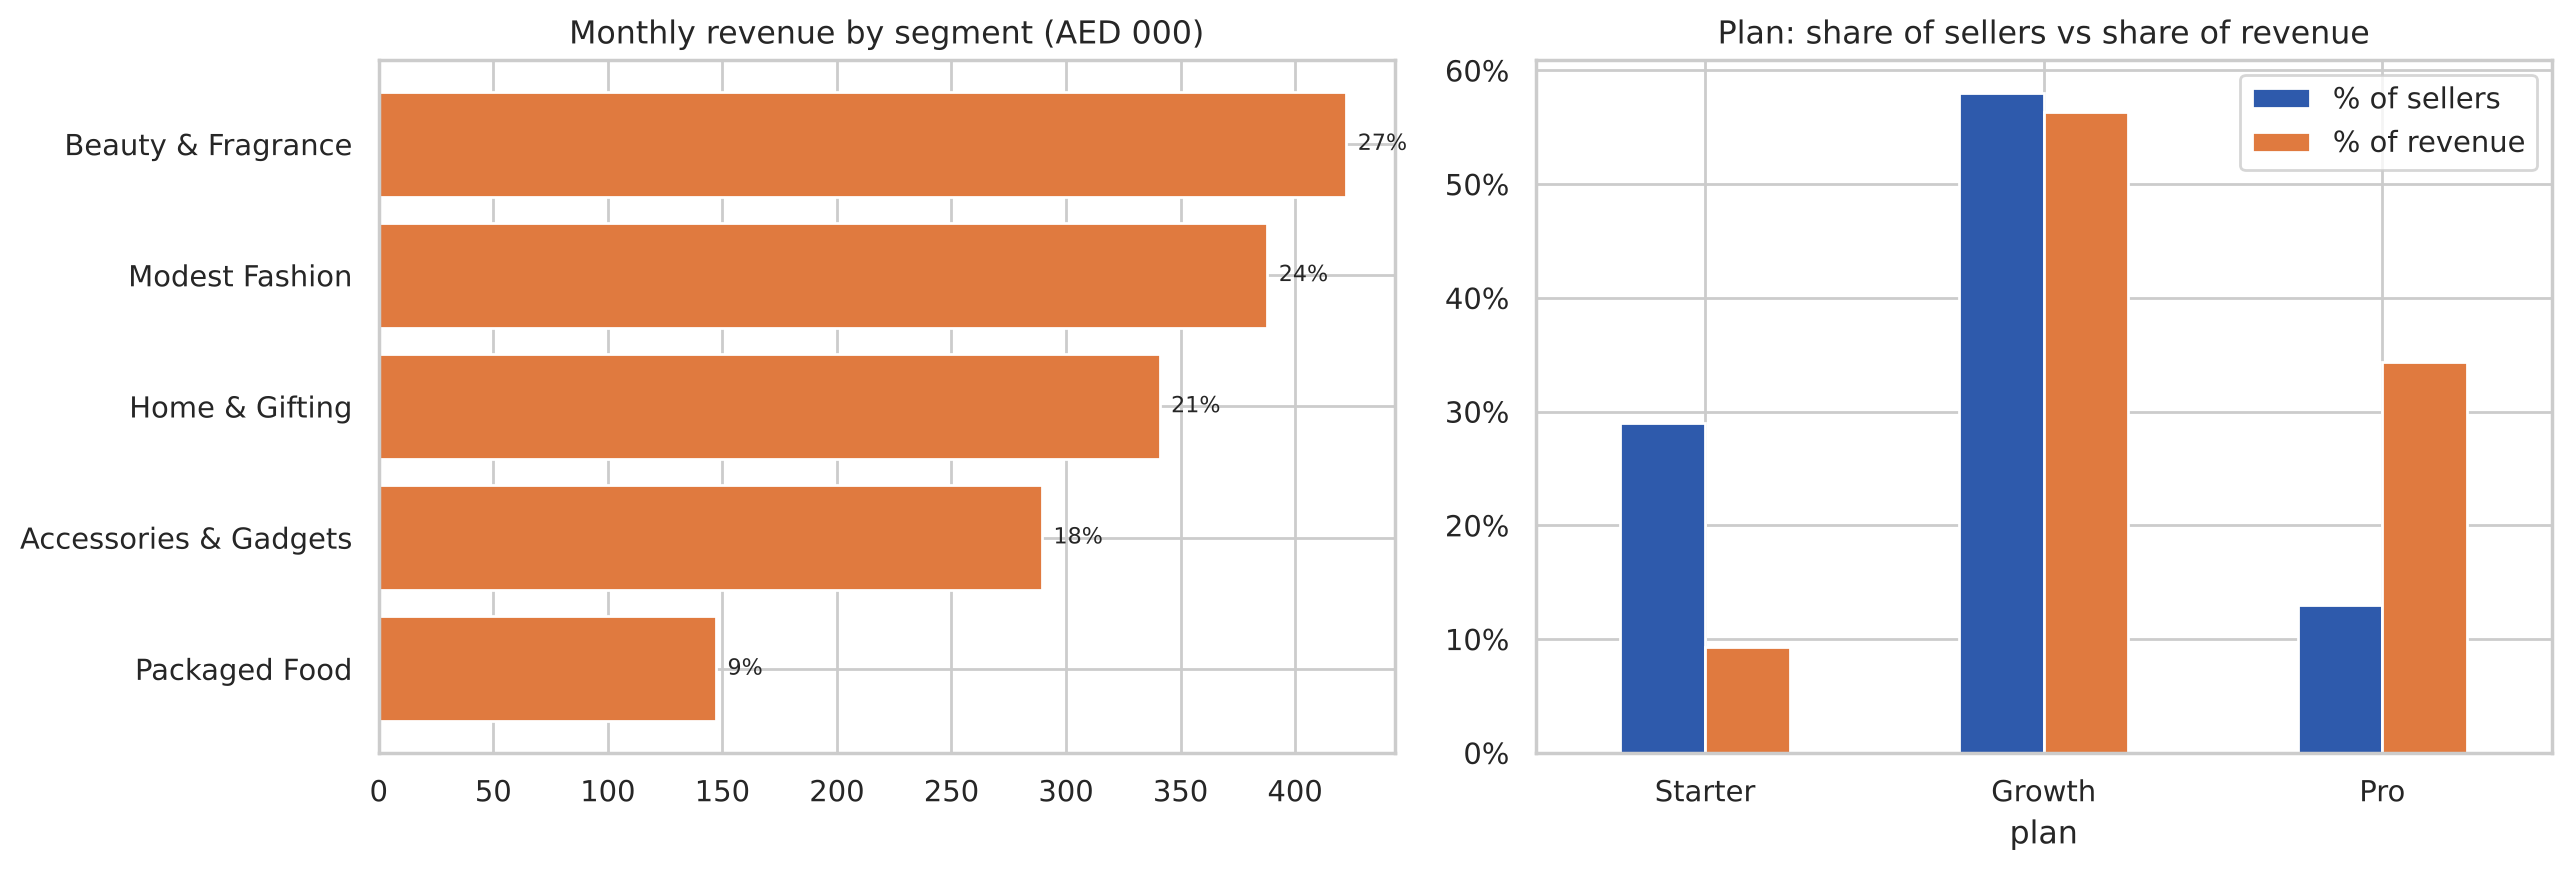

         % of sellers  % of revenue
plan                               
Starter          0.29         0.093
Growth           0.58         0.564
Pro              0.13         0.343
                       sellers   revenue  rev_share
segment                                            
Packaged Food               42  147217.0      0.093
Accessories & Gadgets       80  289512.0      0.182
Home & Gifting              69  340855.0      0.215
Modest Fashion              98  387852.0      0.244
Beauty & Fragrance         111  422307.0      0.266


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
g = df.groupby('segment').agg(sellers=('seller_id', 'count'), revenue=('monthly_revenue_aed', 'sum')).sort_values('revenue')
g['rev_share'] = g.revenue / g.revenue.sum()
ax[0].barh(g.index, g.revenue/1000, color=PAL[1]); ax[0].set_title('Monthly revenue by segment (AED 000)')
for i, (v, s) in enumerate(zip(g.revenue/1000, g.rev_share)): ax[0].text(v+5, i, f'{s:.0%}', va='center', fontsize=8)
p = df.groupby('plan').agg(sellers=('seller_id', 'count'), revenue=('monthly_revenue_aed', 'sum')).reindex(['Starter', 'Growth', 'Pro'])
share = pd.DataFrame({'% of sellers': p.sellers/p.sellers.sum(), '% of revenue': p.revenue/p.revenue.sum()})
share.plot.bar(ax=ax[1], color=[PAL[0], PAL[1]], rot=0); ax[1].set_title('Plan: share of sellers vs share of revenue')
ax[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
save('03_revenue_mix.png'); print(share.round(3)); print(g.round(3))

**Interpretation**
- Beauty (27%) and Fashion (24%) generate half of revenue; Packaged Food is smallest (9%).
- **Pareto effect:** Pro sellers are only **13% of sellers but 34% of revenue**, while Starter sellers are 29% of sellers but only 9% of revenue. Losing one Pro seller ≈ losing 8 Starter sellers.
- **Strategy:** acquisition should target the 150+ orders/month ICP; Starter sellers are only valuable if they grow into Growth/Pro.

---
## 6. Correlation analysis

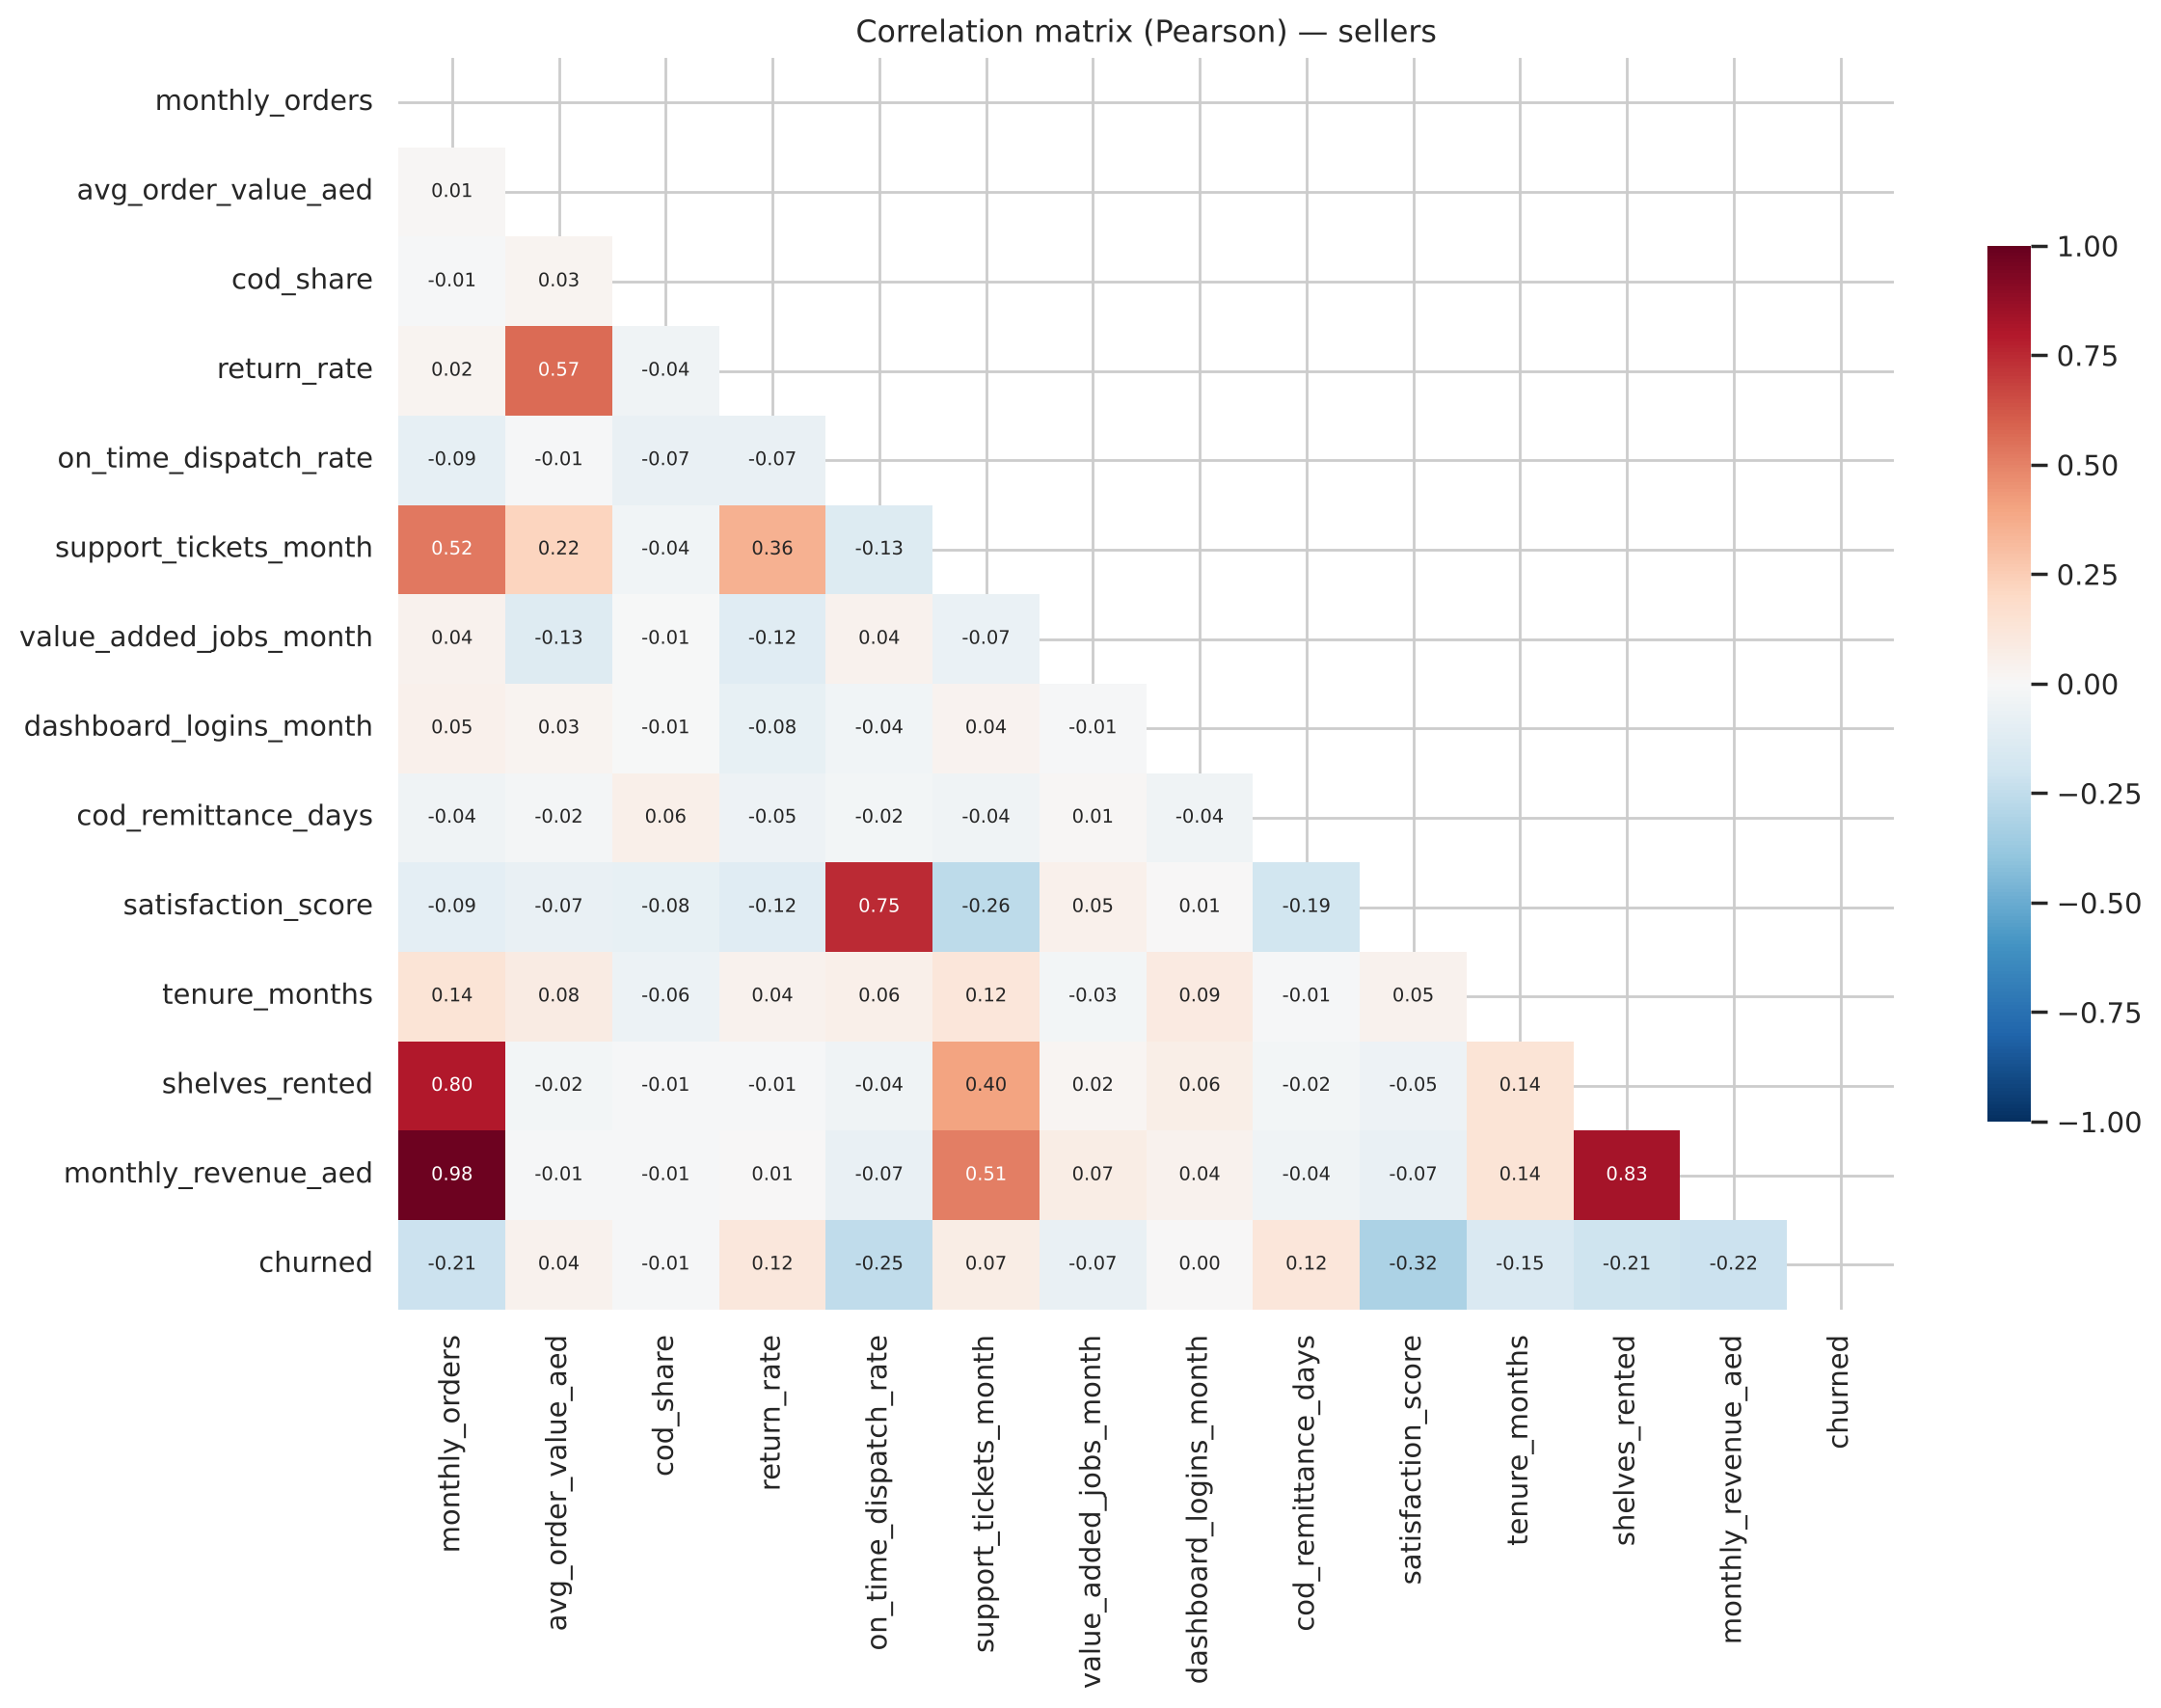

In [14]:
corr = df[num_cols + ['monthly_revenue_aed', 'churned']].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(12, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot_kws={'size': 7}, cbar_kws={'shrink': .7})
plt.title('Correlation matrix (Pearson) — sellers'); save('04_correlation_heatmap.png')

**Interpretation (strongest relationships)**
- **Orders ↔ revenue: r = 0.98** and **shelves ↔ revenue: r = 0.83** — revenue is almost entirely volume-driven (fee model).
- **Dispatch rate ↔ satisfaction: r = 0.75** — the single strongest driver of seller happiness is ShelfIt packing on time.
- **Order value ↔ return rate: r = 0.57** — high-ticket items (abayas, perfumes) get returned more.
- **Tickets ↔ orders: r = 0.52** — bigger sellers naturally raise more tickets (important for the diagnostic below).
- **Churn row:** satisfaction (−0.32), dispatch (−0.25), revenue/orders/shelves (≈ −0.21) all reduce churn; COD payout delay (+0.12) and return rate (+0.12) increase it.
- Near-zero: COD share and dashboard logins have no linear link to anything important.

*Note: correlation ≠ causation; the next section tests these with significance tests.*

---
## 7. Diagnostic analytics — why do sellers churn?
### 7.1 Which numeric factors are linked to churn?
Point-biserial correlation (the correct correlation for a 0/1 target vs a numeric variable).

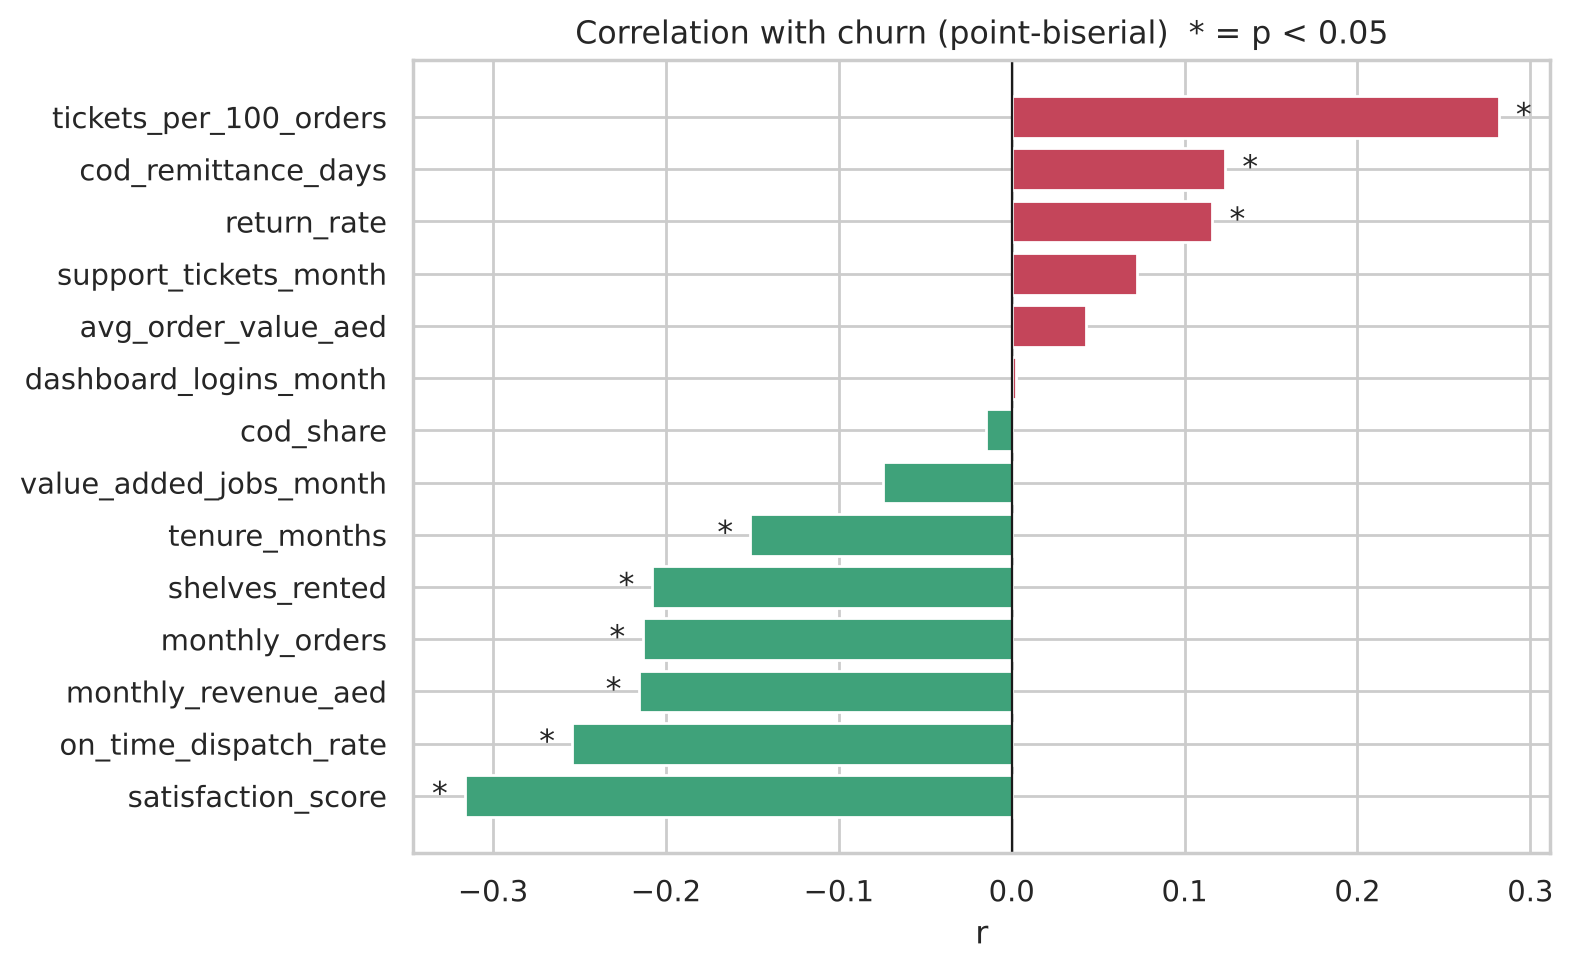

,feature,r_with_churn,p_value
9,satisfaction_score,-0.316,0.000
4,on_time_dispatch_rate,-0.254,0.000
12,monthly_revenue_aed,-0.216,0.000
0,monthly_orders,-0.214,0.000
11,shelves_rented,-0.208,0.000
10,tenure_months,-0.151,0.002
6,value_added_jobs_month,-0.075,0.136
2,cod_share,-0.015,0.766
7,dashboard_logins_month,0.003,0.957
1,avg_order_value_aed,0.043,0.392


In [15]:
rows = []
for c in num_cols + ['monthly_revenue_aed', 'tickets_per_100_orders']:
    r, p = stats.pointbiserialr(df.churned, df[c]); rows.append((c, r, p))
pb = pd.DataFrame(rows, columns=['feature', 'r_with_churn', 'p_value']).sort_values('r_with_churn')
plt.figure(figsize=(8, 5))
plt.barh(pb.feature, pb.r_with_churn, color=[PAL[3] if v > 0 else PAL[2] for v in pb.r_with_churn])
for i, (v, p) in enumerate(zip(pb.r_with_churn, pb.p_value)): plt.text(v + (.01 if v > 0 else -.01), i, '*' if p < .05 else '', ha='left' if v > 0 else 'right', va='center')
plt.axvline(0, c='k', lw=.8); plt.title('Correlation with churn (point-biserial)  * = p < 0.05'); plt.xlabel('r')
save('05_churn_correlation.png'); pb.round(3)

**Interpretation**
- **Satisfaction (r = −0.32)** and **on-time dispatch (−0.25)** are the strongest significant protectors.
- **Raw ticket count is *not* significant (p = 0.15)** — but **tickets per 100 orders is the strongest risk factor (r = +0.28, p < 0.001)**. Big sellers raise many tickets but rarely leave; *small sellers with many problems* leave. The engineered feature exposes a pattern the raw column hid.
- COD payout delay (+0.12) and return rate (+0.12) are smaller but significant churn risks.

### 7.2 Churn across categories (with chi-square tests)

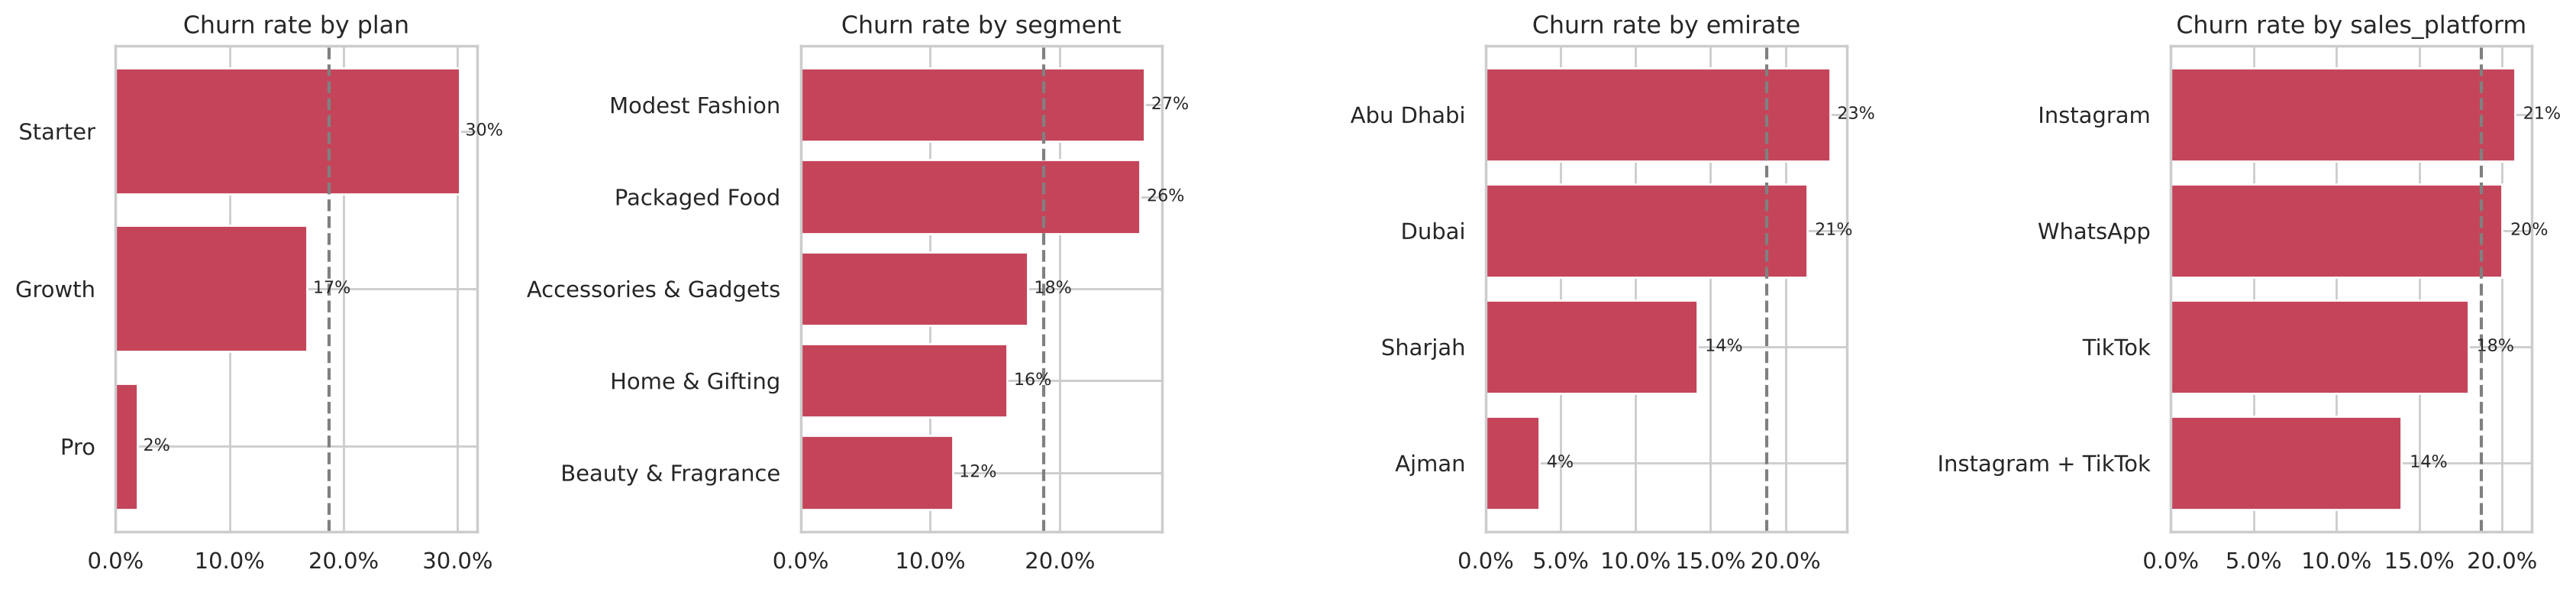

plan            chi2= 20.17  p=0.0000
segment         chi2=  9.47  p=0.0504
emirate         chi2=  7.29  p=0.0633
sales_platform  chi2=  1.79  p=0.6171


In [16]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4))
for a, c in zip(ax, ['plan', 'segment', 'emirate', 'sales_platform']):
    r = df.groupby(c).churned.mean().sort_values(); a.barh(r.index, r.values, color=PAL[3])
    a.axvline(df.churned.mean(), ls='--', c='grey'); a.set_title(f'Churn rate by {c}')
    a.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    for i, v in enumerate(r.values): a.text(v+.005, i, f'{v:.0%}', va='center', fontsize=8)
save('06_churn_by_category.png')
for c in ['plan', 'segment', 'emirate', 'sales_platform']:
    chi2, p, *_ = stats.chi2_contingency(pd.crosstab(df[c], df.churned)); print(f'{c:15s} chi2={chi2:6.2f}  p={p:.4f}')

**Interpretation**
- **Plan is the only clearly significant category (χ² = 20.2, p < 0.001):** Starter 30% vs Growth 17% vs Pro 2%.
- Segment is borderline (p ≈ 0.05): **Modest Fashion (27%) and Packaged Food (26%)** churn most; Beauty least (12%).
- Emirate and platform are **not** significant at 5% — Ajman's 4% is based on few sellers, so it should not drive decisions. Where a seller sells (Instagram vs TikTok) doesn't matter; how ShelfIt serves them does.

### 7.3 Churners vs stayers (box plots + Welch t-tests)

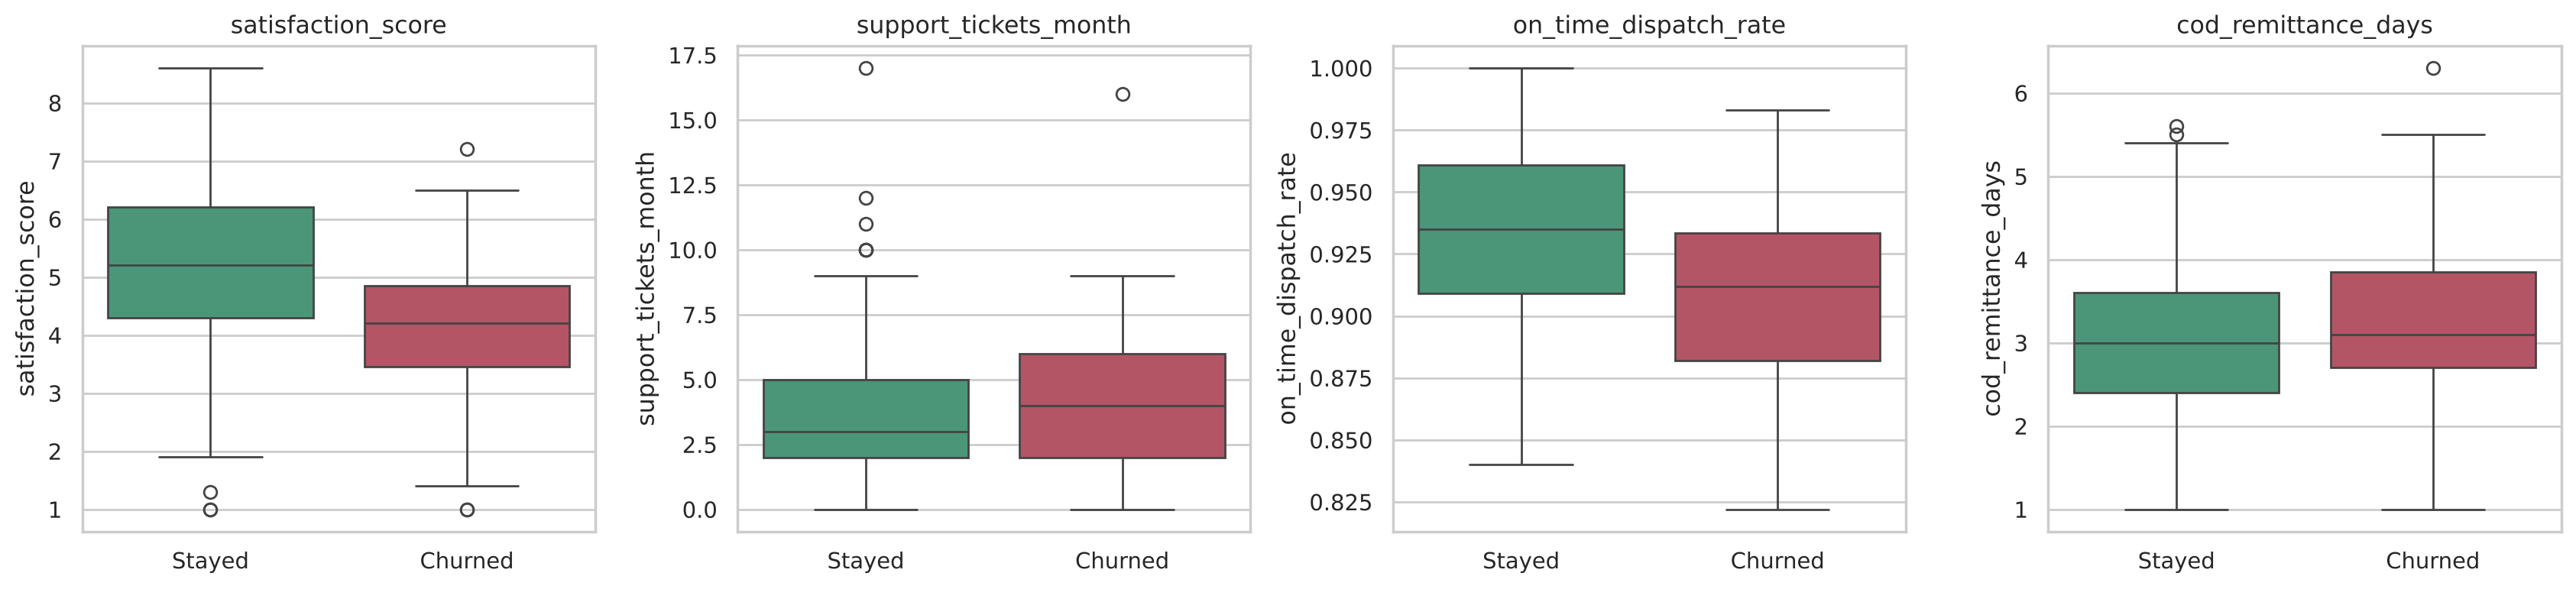

satisfaction_score       stayed=  5.21 churned=  4.05  p=0.0000
support_tickets_month    stayed=  3.64 churned=  4.08  p=0.1785
on_time_dispatch_rate    stayed=  0.94 churned=  0.91  p=0.0000
cod_remittance_days      stayed=  3.03 churned=  3.33  p=0.0139
tenure_months            stayed= 13.95 churned= 11.21  p=0.0029


In [17]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4))
lab = df.churned.map({0: 'Stayed', 1: 'Churned'})
for a, c in zip(ax, ['satisfaction_score', 'support_tickets_month', 'on_time_dispatch_rate', 'cod_remittance_days']):
    sns.boxplot(x=lab, y=df[c], ax=a, palette=[PAL[2], PAL[3]], order=['Stayed', 'Churned']); a.set_title(c); a.set_xlabel('')
save('07_churn_boxplots.png')
for c in ['satisfaction_score', 'support_tickets_month', 'on_time_dispatch_rate', 'cod_remittance_days', 'tenure_months']:
    a, b = df[df.churned == 0][c], df[df.churned == 1][c]; t, p = stats.ttest_ind(a, b, equal_var=False)
    print(f'{c:24s} stayed={a.mean():6.2f} churned={b.mean():6.2f}  p={p:.4f}')

**Interpretation**
- Churners have clearly **lower satisfaction (4.05 vs 5.21)**, **worse dispatch (91% vs 94%)**, **slower COD payouts (3.3 vs 3.0 days)** and **shorter tenure (11.2 vs 14.0 months)** — all significant (p < 0.05).
- Raw ticket counts overlap heavily (p = 0.18), confirming 7.1.
- **Diagnosis:** churn is a *service-quality* problem (late dispatch → low CSAT → exit), amplified for small, new sellers.

### 7.4 Interaction: tenure, satisfaction and plan

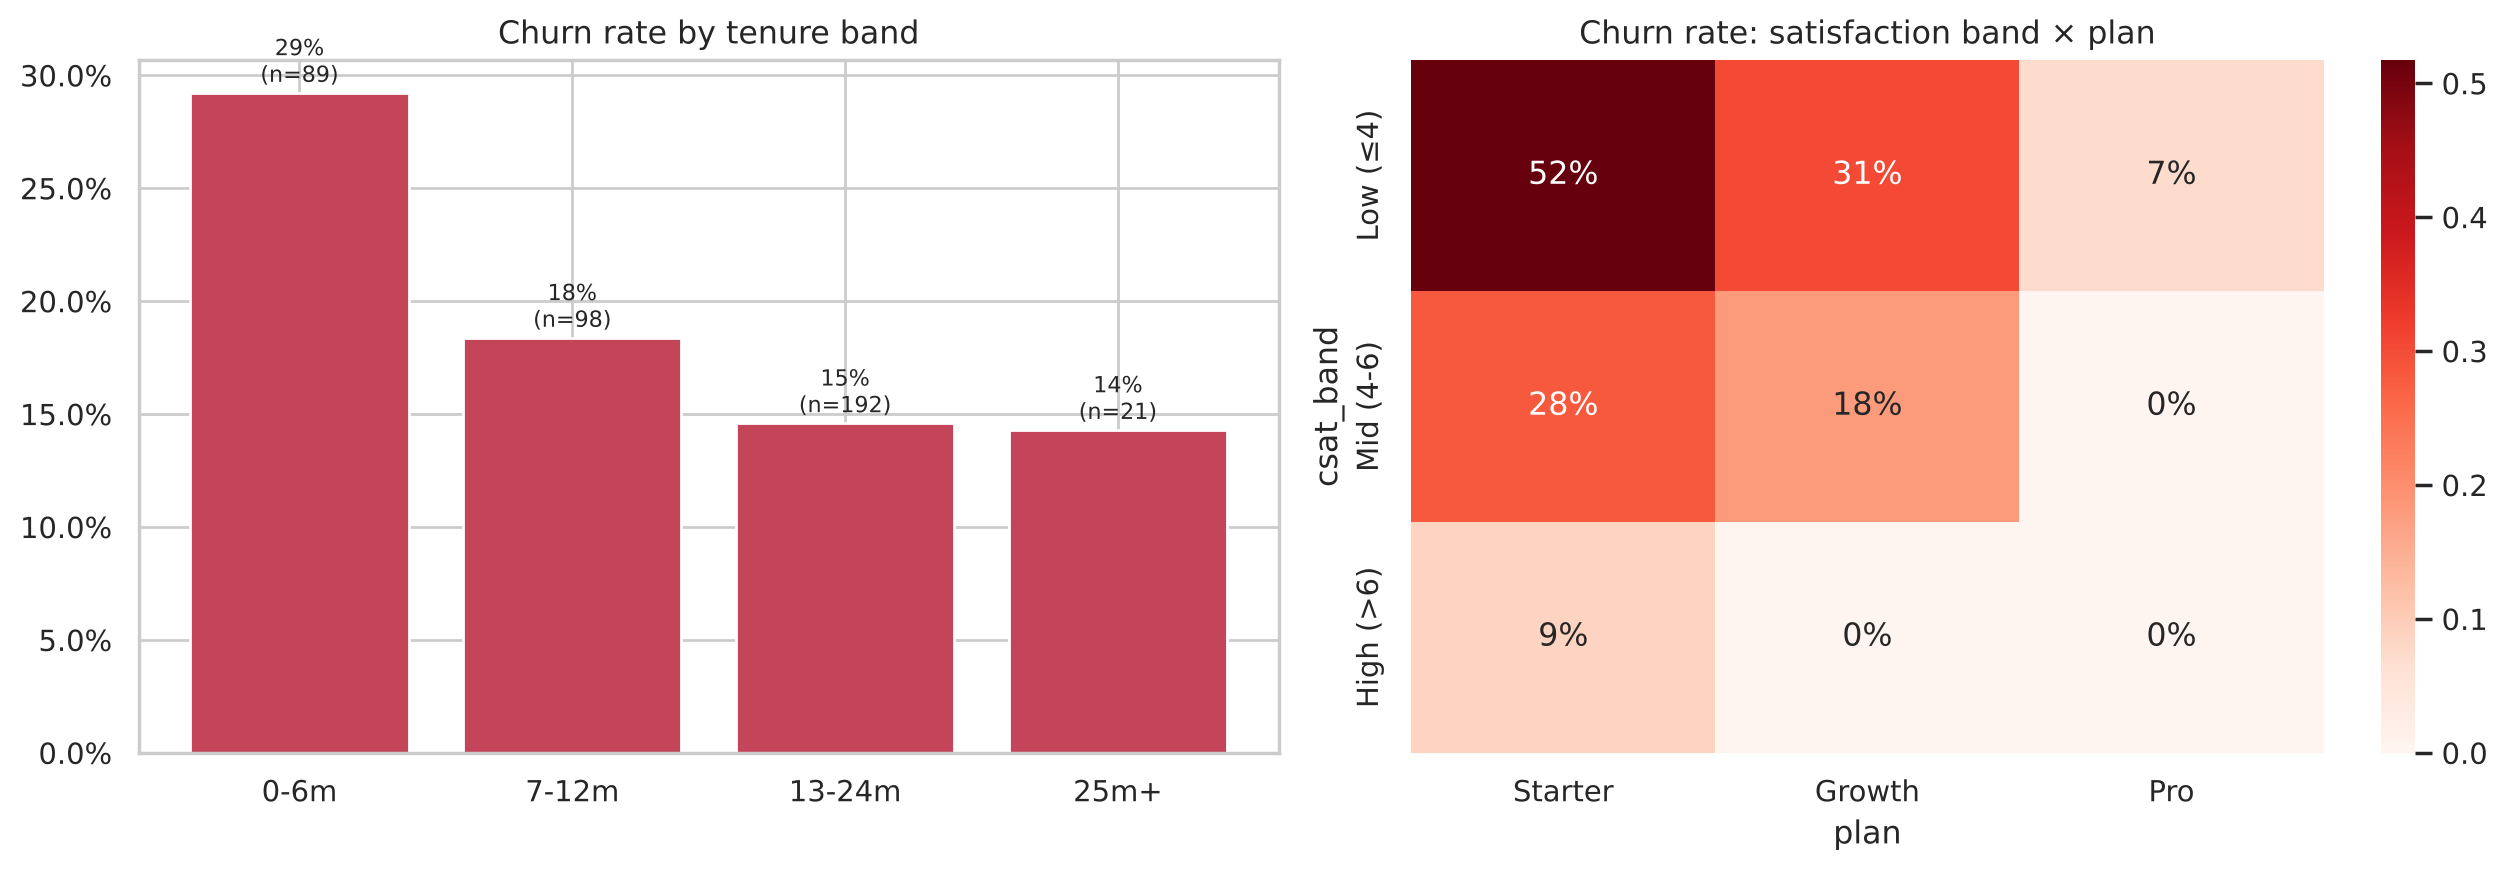

              mean  count
tenure_band              
0-6m         0.292     89
7-12m        0.184     98
13-24m       0.146    192
25m+         0.143     21
plan       Starter  Growth    Pro
csat_band                        
Low (≤4)     0.517   0.305  0.071
Mid (4-6)    0.281   0.181  0.000
High (>6)    0.087   0.000  0.000


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
t = df.groupby('tenure_band', observed=True).churned.agg(['mean', 'count'])
ax[0].bar(t.index.astype(str), t['mean'], color=PAL[3]); ax[0].set_title('Churn rate by tenure band')
for i, (v, n) in enumerate(zip(t['mean'], t['count'])): ax[0].text(i, v+.005, f'{v:.0%}\n(n={n})', ha='center', fontsize=8)
ct = pd.crosstab(df.csat_band, df.plan, values=df.churned, aggfunc='mean').reindex(columns=['Starter', 'Growth', 'Pro'])
sns.heatmap(ct, annot=True, fmt='.0%', cmap='Reds', ax=ax[1]); ax[1].set_title('Churn rate: satisfaction band × plan')
for a in [ax[0]]: a.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
save('08_churn_tenure_csat.png'); print(t.round(3)); print(ct.round(3))

**Interpretation**
- **Left:** churn is highest in the **first 6 months (29%)** and halves after a year (15%). The first months are the danger zone → onboarding matters.
- **Right:** the worst combination is **Starter + low satisfaction = 52% churn**. Even unhappy Pro sellers rarely leave (7%), and *no* Growth/Pro seller with high satisfaction churned.
- **Action:** an early-warning rule ("Starter or tenure < 6m AND CSAT ≤ 4") would flag the riskiest group for a call.

---
## 8. Diagnostic analytics — revenue & service
### 8.1 What drives revenue per seller?

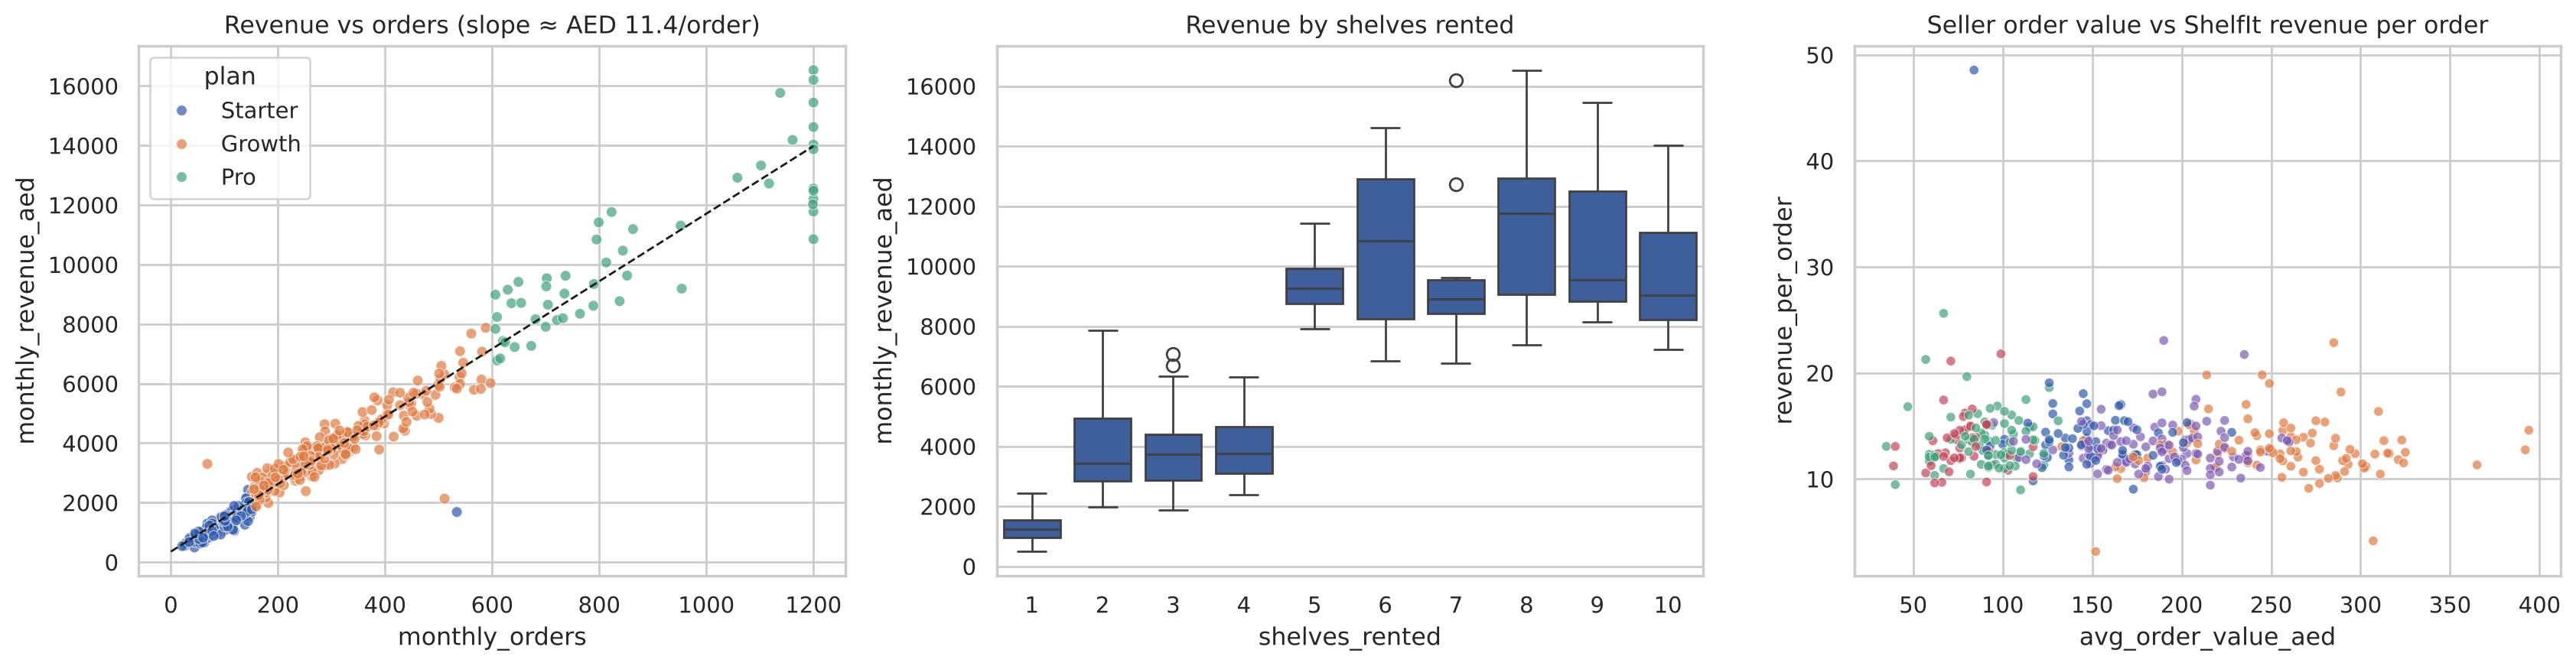

r(orders,revenue)= 0.977 | r(AOV, rev/order)= -0.116


In [19]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=df, x='monthly_orders', y='monthly_revenue_aed', hue='plan', hue_order=['Starter', 'Growth', 'Pro'], ax=ax[0], s=25, alpha=.7)
m, c0 = np.polyfit(df.monthly_orders, df.monthly_revenue_aed, 1); xs = np.linspace(0, df.monthly_orders.max(), 50)
ax[0].plot(xs, m*xs+c0, 'k--', lw=1); ax[0].set_title(f'Revenue vs orders (slope ≈ AED {m:.1f}/order)')
sns.boxplot(data=df, x='shelves_rented', y='monthly_revenue_aed', ax=ax[1], color=PAL[0]); ax[1].set_title('Revenue by shelves rented')
sns.scatterplot(data=df, x='avg_order_value_aed', y='revenue_per_order', hue='segment', ax=ax[2], s=20, alpha=.7, legend=False)
ax[2].set_title('Seller order value vs ShelfIt revenue per order')
save('09_revenue_drivers.png')
print('r(orders,revenue)=', round(df.monthly_orders.corr(df.monthly_revenue_aed), 3), '| r(AOV, rev/order)=', round(df.avg_order_value_aed.corr(df.revenue_per_order), 3))

**Interpretation**
- **Left:** a near-perfect straight line (r = 0.98) with a slope of **≈ AED 11.35 per extra order**, close to the plan's AED 10 assumption (the extra comes from storage/VAS scaling with size). Plans form clear bands along the line.
- **Middle:** revenue rises steadily with each extra shelf → **shelf upsell** is a direct revenue lever.
- **Right:** a seller's order value has **no link** with ShelfIt's revenue per order (r = −0.12). ShelfIt earns the same for a AED 400 abaya as for a AED 50 phone case. → opportunity for value-based add-ons (e.g. insurance/premium handling for high-value items).

### 8.2 Service quality: returns, tickets and COD payouts

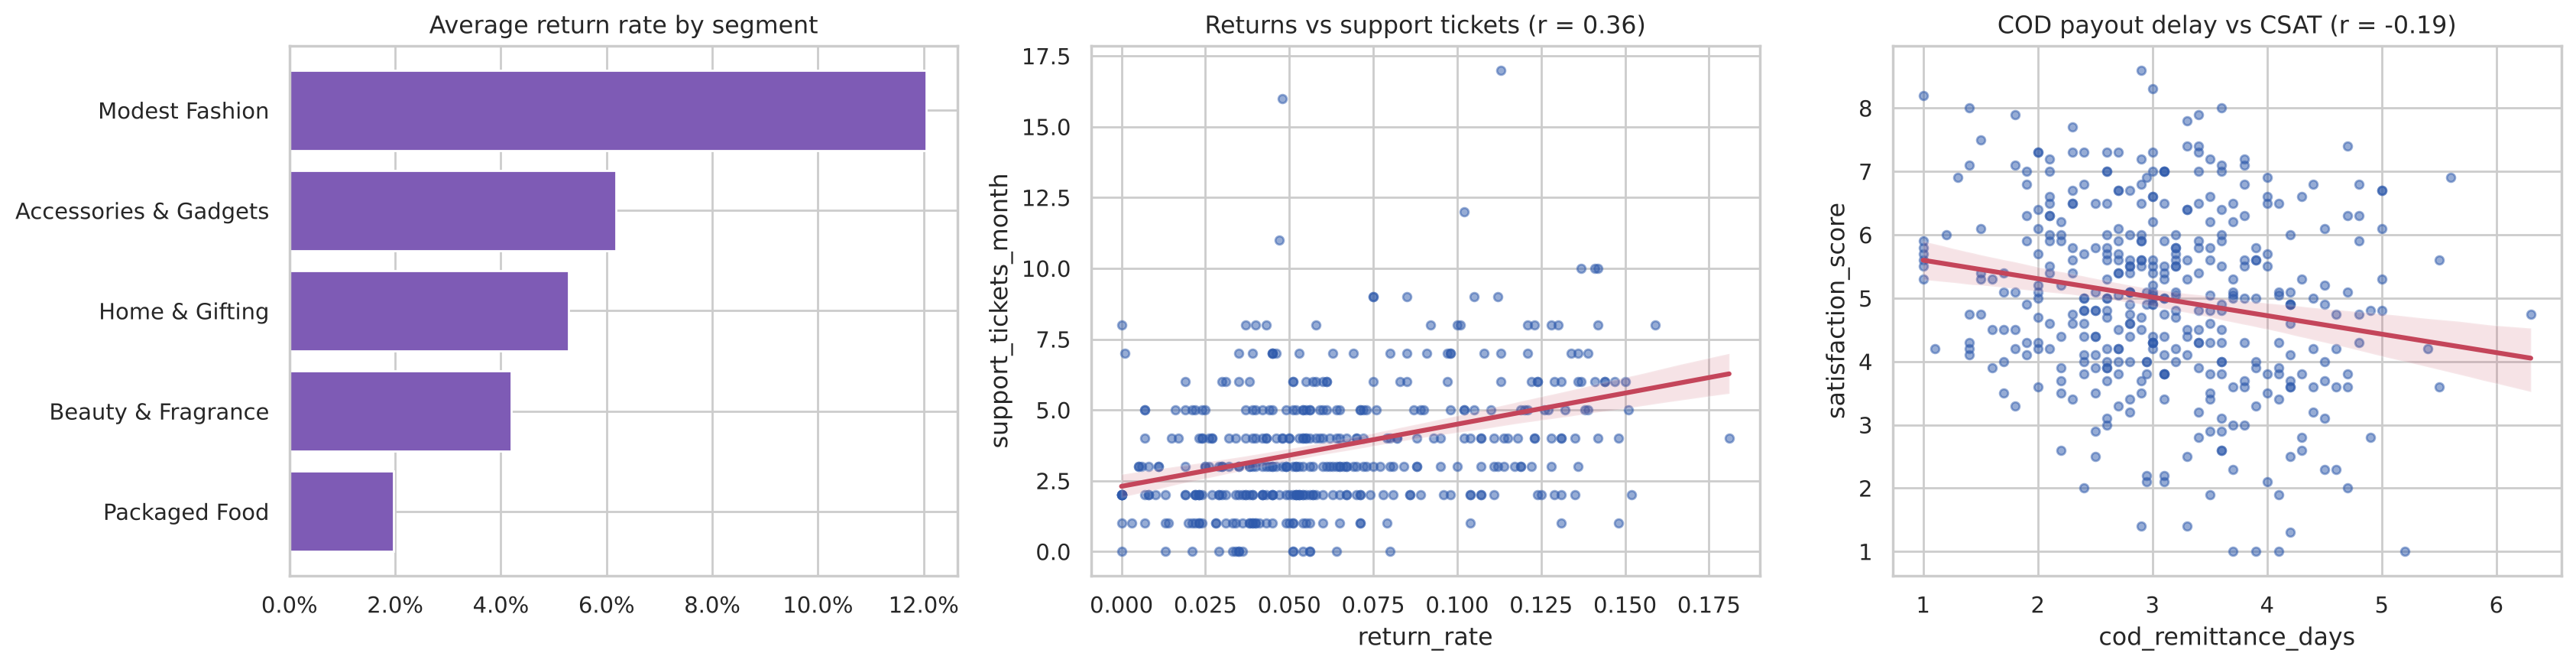

                       return_rate  avg_order_value_aed
segment                                                
Packaged Food                0.020               77.524
Beauty & Fragrance           0.042              185.667
Home & Gifting               0.053              148.101
Accessories & Gadgets        0.062               89.675
Modest Fashion               0.120              253.929


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
r = df.groupby('segment')[['return_rate', 'avg_order_value_aed']].mean().sort_values('return_rate')
ax[0].barh(r.index, r.return_rate, color=PAL[4]); ax[0].set_title('Average return rate by segment')
ax[0].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
sns.regplot(data=df, x='return_rate', y='support_tickets_month', ax=ax[1], scatter_kws={'s': 15, 'alpha': .5}, line_kws={'color': PAL[3]})
ax[1].set_title(f"Returns vs support tickets (r = {df.return_rate.corr(df.support_tickets_month):.2f})")
sns.regplot(data=df, x='cod_remittance_days', y='satisfaction_score', ax=ax[2], scatter_kws={'s': 15, 'alpha': .5}, line_kws={'color': PAL[3]})
ax[2].set_title(f"COD payout delay vs CSAT (r = {df.cod_remittance_days.corr(df.satisfaction_score):.2f})")
save('10_service_quality.png'); print(r.round(3))

**Interpretation**
- **Left:** Modest Fashion's return rate (**12%**) is ~2–6× other segments (size/fit issues) — explains its high churn.
- **Middle:** sellers with more returns raise more tickets (r = 0.36) — returns create operational load.
- **Right:** slower COD payouts lower satisfaction (r = −0.19). Faster remittance is a cheap way to lift CSAT.
- **Action:** a dedicated returns package for fashion sellers and a 48-hour COD payout promise.

### 8.3 Service usage across 5,745 orders

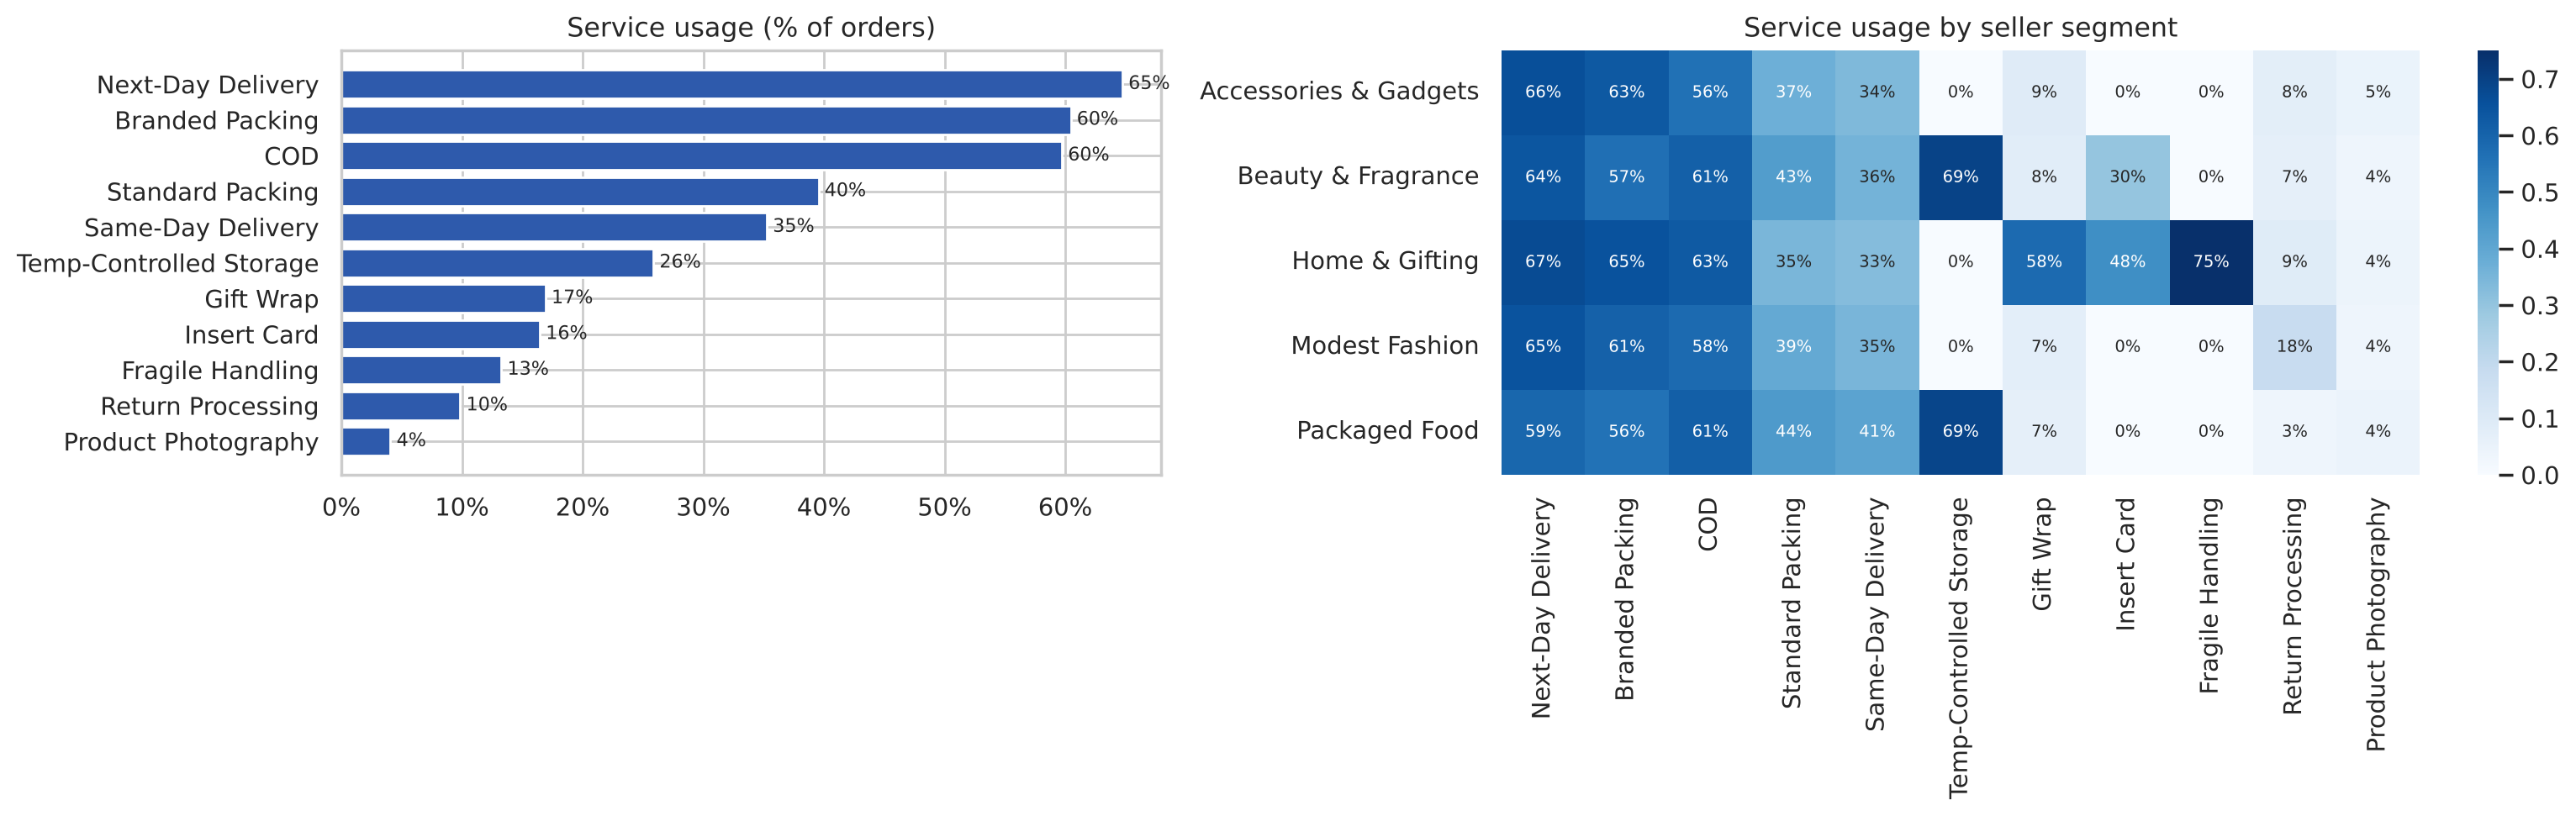

In [21]:
use = orders[SERVICES].mean().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1, 1.4]})
ax[0].barh(use.index, use.values, color=PAL[0]); ax[0].set_title('Service usage (% of orders)')
ax[0].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
for i, v in enumerate(use.values): ax[0].text(v+.005, i, f'{v:.0%}', va='center', fontsize=8)
seg_use = orders.groupby('segment')[SERVICES].mean()
sns.heatmap(seg_use[use.index[::-1]], annot=True, fmt='.0%', cmap='Blues', ax=ax[1], annot_kws={'size': 7})
ax[1].set_title('Service usage by seller segment'); ax[1].set_ylabel('')
save('11_service_usage.png')

**Interpretation**
- **COD on 60% of orders** and **branded packing on 60%** — the core proposition is used as intended.
- **Heatmap:** usage is segment-specific — Home & Gifting dominates fragile handling and gift wrap; Beauty and Food use temperature-controlled storage (UAE heat); Fashion has the highest return processing.
- **Action:** warehouse zones and staffing should follow segment mix (cold zone for beauty/food, gift station for gifting).

### 8.4 Which services are used together? (co-occurrence lift)
Lift = P(A and B) ÷ (P(A) × P(B)). Lift > 1 means the two services appear together more than chance.

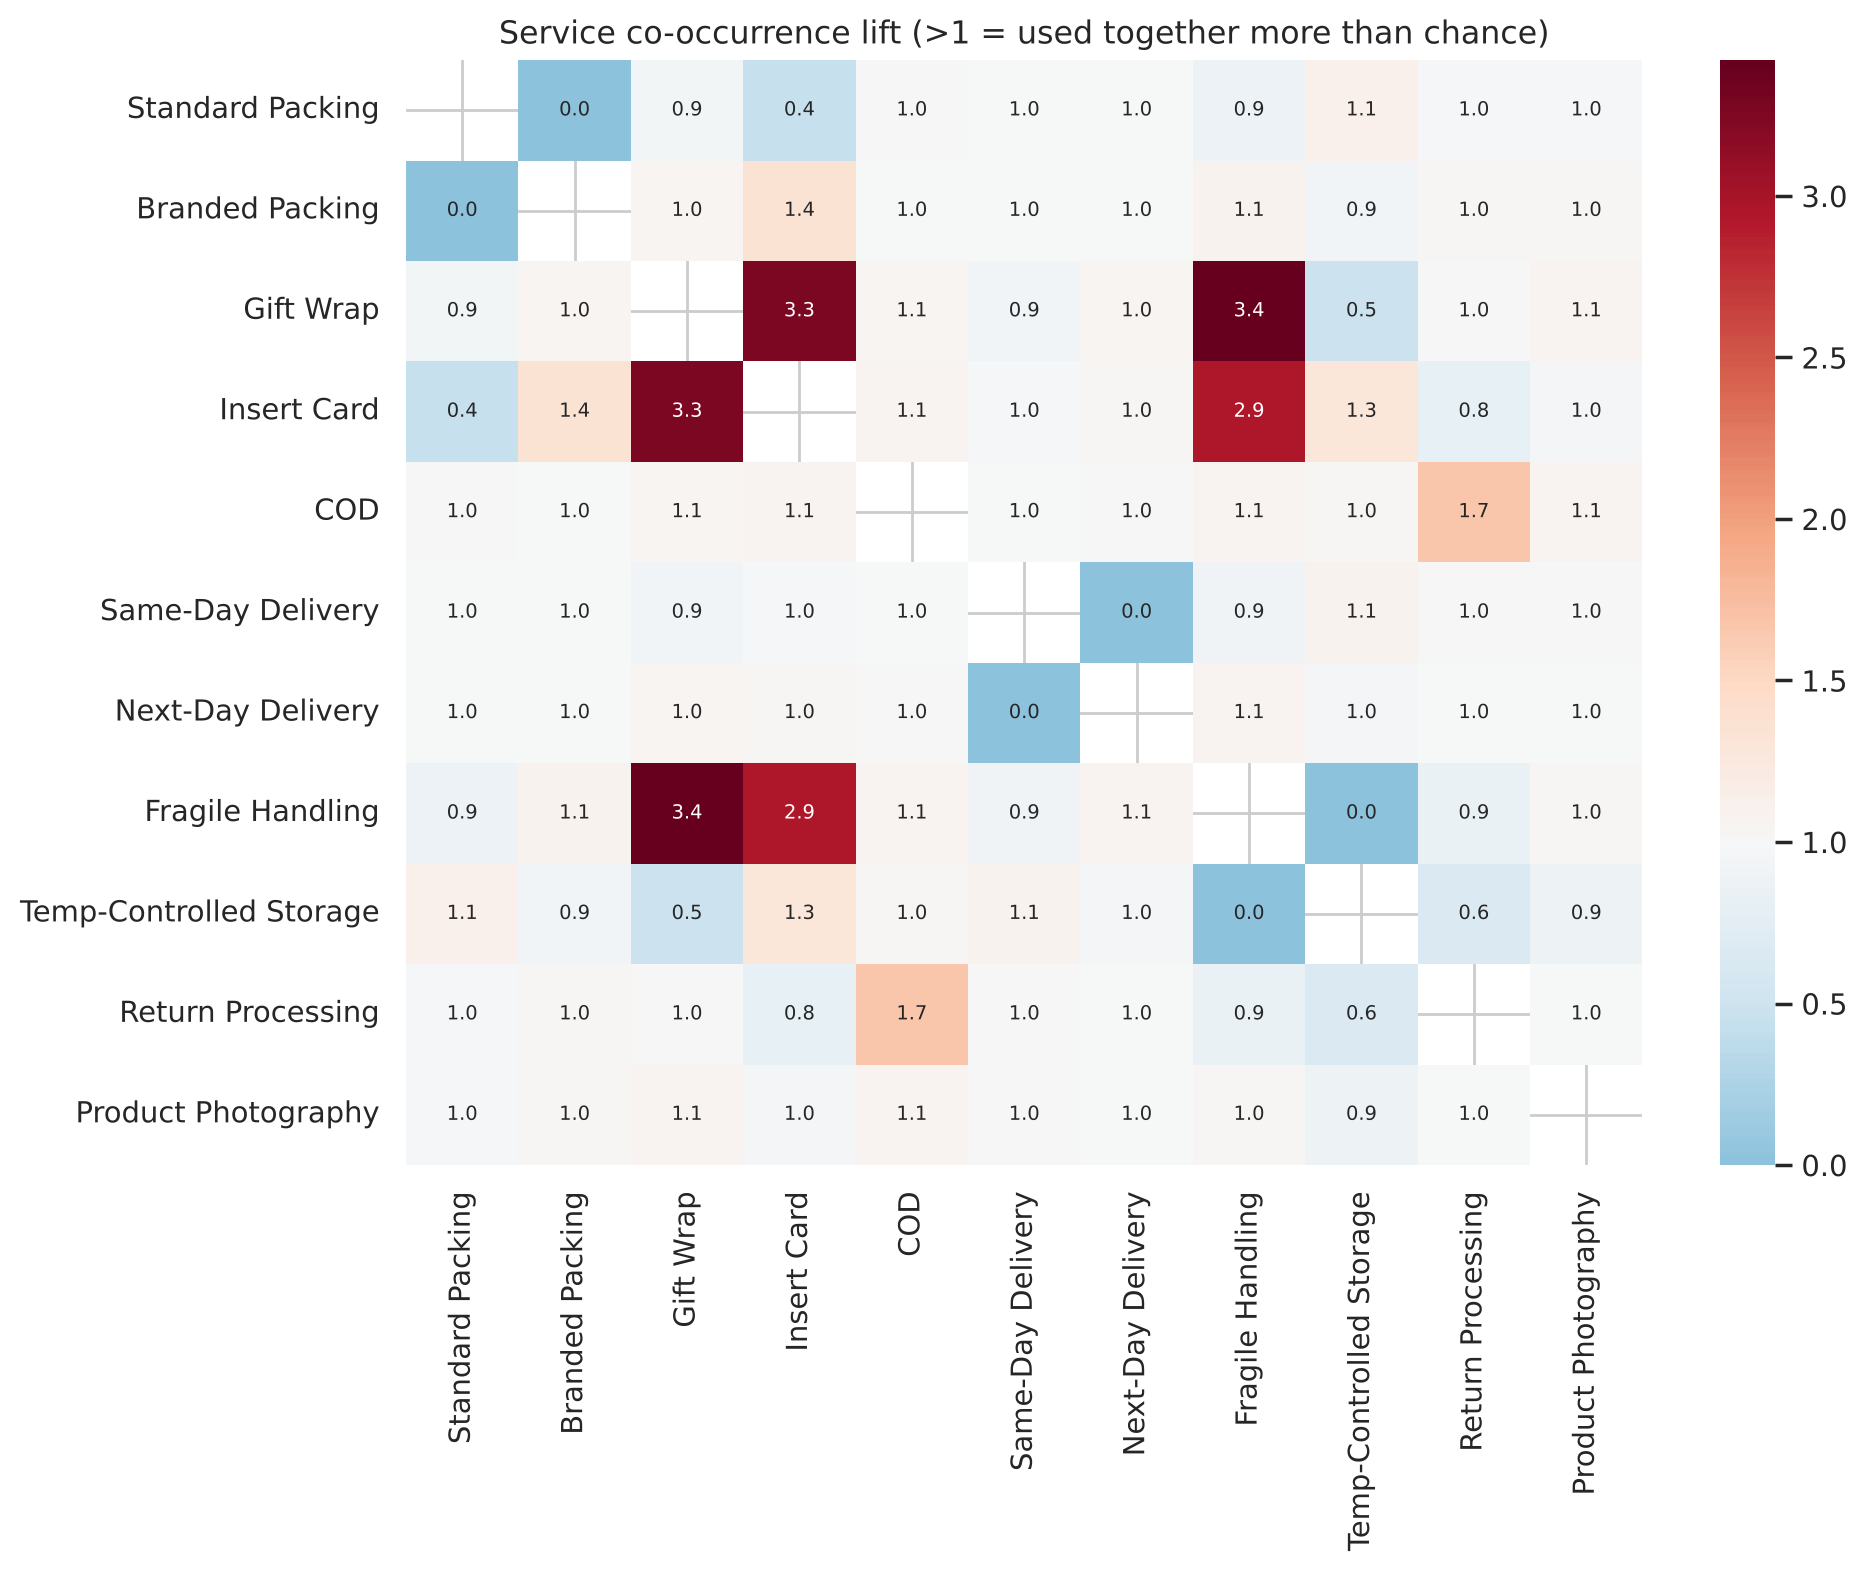

Gift Wrap        Fragile Handling           3.42
                 Insert Card                3.28
Insert Card      Fragile Handling           2.94
COD              Return Processing          1.67
Branded Packing  Insert Card                1.36
Insert Card      Temp-Controlled Storage    1.28
dtype: float64

In [22]:
co = orders[SERVICES].T.dot(orders[SERVICES]) / len(orders)
expected = np.outer(orders[SERVICES].mean(), orders[SERVICES].mean())
lift = co / expected
for s_ in SERVICES: lift.loc[s_, s_] = np.nan
plt.figure(figsize=(10, 8))
sns.heatmap(lift, annot=True, fmt='.1f', cmap='RdBu_r', center=1, annot_kws={'size': 7})
plt.title('Service co-occurrence lift (>1 = used together more than chance)')
save('12_service_cooccurrence.png')
top = lift.where(np.triu(np.ones(lift.shape), 1).astype(bool)).stack().sort_values(ascending=False)
top.head(6).round(2)

**Interpretation**
- **Gift wrap + fragile handling (lift 3.4)**, **gift wrap + insert card (3.3)** and **insert card + fragile (2.9)** form a natural **"Gift-Ready" bundle**.
- **COD + return processing (1.7):** returns come from COD orders — customers who haven't paid are more likely to refuse.
- Same-day vs next-day and branded vs standard packing show lift ≈ 0 because they are alternatives.
- This preview is followed up properly with **association rule mining (Apriori)** in the group phase.

---
## 9. Summary — business diagnosis

In [23]:
summary = pd.DataFrame([
 ('Churn by plan (Starter vs Pro)', f"{df[df.plan=='Starter'].churned.mean():.0%} vs {df[df.plan=='Pro'].churned.mean():.0%}"),
 ('Churn: low vs high CSAT', f"{df[df.csat_band=='Low (≤4)'].churned.mean():.0%} vs {df[df.csat_band=='High (>6)'].churned.mean():.0%}"),
 ('Revenue per extra order (AED)', round(m, 2)),
 ('Pro plan: % sellers / % revenue', f"{share.loc['Pro','% of sellers']:.0%} / {share.loc['Pro','% of revenue']:.0%}"),
 ('Highest return-rate segment', r.return_rate.idxmax()),
], columns=['Insight', 'Value']); summary

,Insight,Value
0,Churn by plan (Starter vs Pro),30% vs 2%
1,Churn: low vs high CSAT,33% vs 2%
2,Revenue per extra order (AED),11.35
3,Pro plan: % sellers / % revenue,13% / 34%
4,Highest return-rate segment,Modest Fashion


### Key findings
1. **The business plan holds up:** AED 3,969 revenue/seller (plan: 3,200) and ≈ AED 11 per order (plan: 10).
2. **Revenue is concentrated:** Pro sellers = 13% of sellers but 34% of revenue.
3. **Churn (18.8%) is the main risk, and it is diagnosable:** it is driven by low satisfaction, late dispatch, slow COD payouts, problems per order, short tenure and the Starter plan — not by platform or location.
4. **Segment problems:** Modest Fashion has 2× the returns and the highest churn.
5. **Natural service bundles exist** (gift wrap + fragile + insert card).

### Strategic recommendations
| Priority | Action | Evidence |
|---|---|---|
| 1 | Keep on-time dispatch ≥ 95% (SLA + staffing) | Dispatch ↔ CSAT r = 0.75; churners 91% vs 94% |
| 2 | 90-day onboarding programme for new/Starter sellers | 29% churn in first 6 months; Starter 30% |
| 3 | 48-hour COD payout guarantee | COD delay ↑ churn and ↓ CSAT |
| 4 | Fashion returns package | 12% returns, 27% churn |
| 5 | Shelf upsell + "Gift-Ready" bundle | Revenue rises per shelf; lift 3.3–3.4 |
| 6 | Monthly early-warning list (Starter/new + CSAT ≤ 4) | 52% churn in that cell |

### Next (group phase)
Classification (churn prediction), clustering (seller personas), association rule mining (service bundles) and Linear/Ridge/Lasso regression (revenue) on the cleaned, model-ready data.